# H₄のポテンシャル曲線

## 状態準備回路（$R=2.0\,\mathrm{\mathring A}$）

直鎖H₄、隣り合うH原子の距離 $R=2.0\,\mathrm{\mathring A}$、STO-3G、4電子・4空間軌道を扱います。
軌道はBoys局在化＋軌道順最適化、系は8量子ビットです。
対象は基底一重項 $S_0$ と最低三重項の $M_S=0$ 成分 $T_0$ です。

MPSの最大ボンド次元は $\chi=6$ に固定します。$M$ は隣接2量子ビットゲートを交互に並べる回路の層数です。
**MPSへの近似と、MPSを有限層の回路にする近似を分けて確認します。**

$$F_{\mathrm{MPS}}=|\langle\psi_{\mathrm{FCI}}|\psi_{\mathrm{MPS}}\rangle|^2,
\qquad F_{\mathrm{circ}}=|\langle\psi_{\mathrm{FCI}}|P|0^8\rangle|^2.$$

| $\chi$ | $M$ | $F_{\mathrm{MPS}}(S_0)$ | $F_{\mathrm{MPS}}(T_0)$ | $F_{\mathrm{circ}}(S_0)$ | $F_{\mathrm{circ}}(T_0)$ | CX数（$P_0$ / $P_T$） |
|---:|---:|---:|---:|---:|---:|---:|
| 6 | 4 | 1.0000000000 | 1.0000000000 | 0.7472368749 | 0.5350118068 | 42 / 40 |
| 6 | 6 | 1.0000000000 | 1.0000000000 | 0.9385998057 | 0.9995639803 | 60 / 60 |
| 6 | 8 | 1.0000000000 | 1.0000000000 | 0.9994591651 | 0.9999941418 | 80 / 80 |
| — | 厳密準備回路 | — | — | 1（数値精度） | 1（数値精度） | 254 / 254 |

CX数は各状態を準備する回路 $P_k$ を `rz/sx/x/cx` に分解した後の値です。
S₀・T₀を枝分けして準備する補助ビット付き回路 $A$ や、逆準備 $A^\dagger$ の費用は含めません。

厳密準備回路はFCI振幅からRy/CXで直接合成したもので、MPSへの近似や有限層回路へのフィットを経由しません。

## 時間発展回路（$R=2.0\,\mathrm{\mathring A}$）

状態準備と同じ軌道・電子Hamiltonianを使い、一歩の時間発展
$$U_{\mathrm{exact}}(\Delta t)=e^{-iH\Delta t},\qquad \Delta t=0.1\ \mathrm{a.u.}$$
をMPOで表し、有限層数 $M$ の回路に近似します。ここでの $M$ は**時間発展回路の層数**です。
状態準備の $M$ とは独立に選びます。

保存されたM=8・16・32の回路は、同じ参照MPO（二次Trotter100分割、SVD cutoff=$10^{-18}$）を使っています。
MPO化後の忠実度は正規化Hilbert–Schmidt重なり、回路化後は厳密な $U_{\mathrm{exact}}$ との重なりです。

$$F_{\mathrm{MPO}}=
\frac{|\mathrm{Tr}(U_{\mathrm{exact}}^\dagger V_{\mathrm{MPO}})|^2}
{\mathrm{Tr}(U_{\mathrm{exact}}^\dagger U_{\mathrm{exact}})\,\mathrm{Tr}(V_{\mathrm{MPO}}^\dagger V_{\mathrm{MPO}})},
\qquad F_{\mathrm{circ}}=
\left|\frac{\mathrm{Tr}(U_{\mathrm{exact}}^\dagger U_{\mathrm{circ}})}{256}\right|^2.$$

| 時間発展回路 | MPO化後 $F_{\mathrm{MPO}}$ | 回路化後 $F_{\mathrm{circ}}$ | 2量子ビットブロック数 | CX数（順変換なし） | CX数（符号付き順変換込み） |
|---|---:|---:|---:|---:|---:|
| MPO回路（$M=8$） | 0.9999999999997 | 0.999849275337 | 28 | 84 | 132 |
| MPO回路（$M=16$） | 0.9999999999997 | 0.999999858223 | 56 | 168 | 216 |
| MPO回路（$M=32$） | 0.9999999999997 | 0.999999998019 | 112 | 336 | 384 |
| 1st-order Trotter | — | 0.999999883621 | — | 1204 | 1204 |
| 2nd-order Trotter | — | 0.999999999992 | — | 2406 | 2406 |

CX数は `rz/sx/x/cx` への分解後の値です。ブロック数は順変換を除いたU(4)ゲート数です。
右端は、状態準備と同じスピン軌道順で使うための符号付きFock順変換を前後に含めた値です。
これらは時間発展一歩の回路費用であり、状態準備・逆準備・時間反復 $L$ の費用は含みません。

MPOと回路の忠実度はどちらも厳密な時間発展を参照しています。高い演算子忠実度だけで、目的の二状態のエネルギー差の精度まで保証されるわけではありません。

Trotterの2行は、同じ電子HamiltonianのPauli展開（361項）から作った**分割数1、一歩 $\Delta t=0.1$**の回路です。
1次はLie–Trotter、2次は対称Suzuki–Trotterです。MPOを経由せず、MPO回路の層数Mとも区別します。
準備と同じスピン軌道順で直接構成するため、追加のFock順変換は不要で、二つのCX列は同じ値です。
CX数は全結合条件で `rz/sx/x/cx` に分解・最適化した値（Qiskit 2.4.1、optimization_level=1、seed_transpiler=7）です。

## 実行準備

以下はすべてシミュレーションです。IBMアカウント・APIキーは使いません。
Colabの初回は次セルの `%pip` 行のコメントを外して実行してください。
20構造の保存データは、不足ファイルだけ固定版GitHubから取得し、SHA-256を確認して再利用します。最適化は再実行しません。

保存先の優先順は05・06と同じく、`H4_DATA_DIR`環境変数 → `H4_CACHE_DIR` → 取得済みリポジトリ → `~/.cache/ftqc_handson/h4_pec_v1`です。
指定した保存先にデータがなければ、その場所へダウンロードします。次の初期化セル先頭の`H4_CACHE_DIR`を変更してください。
ローカルなら、例えば`H4_CACHE_DIR = '/自分の保存先/h4_pec_v1'`と指定できます。
従来の保存データを使う場合は`H4_CACHE_DIR = 'outputs/h4_pec_v1'`も指定できます。

Google Driveへ保存するときは、先に別セルでmountし、その後、初期化セル先頭の設定を書き換えて実行します。

```python
from google.colab import drive
drive.mount('/content/drive')
# 次の初期化セル先頭を変更:
# H4_CACHE_DIR = '/content/drive/MyDrive/FTQC_HandsOn/h4_pec_v1'
```

同じ保存先を指定すれば、再起動後も保存済みファイルを再利用します。設定変更後は初期化セル以降を再実行してください。
Colabで既定のランタイム内へ保存したデータは、ランタイムを破棄すると失われます。Driveに保存したデータは次回も使えます。

In [1]:
# 初回だけコメントを外して実行してください。
# %pip -q install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"


In [2]:
# 保存先を変える場合は、この値を変更してから実行してください。
H4_CACHE_DIR = None  # 例: '/content/drive/MyDrive/FTQC_HandsOn/h4_pec_v1'

H4_INDEX = {'version': 'h4-pec-v1', 'dt': 0.1, 'modes': 'alpha0..3,beta0..3', 'geometry': 'linear equally spaced H4; R is adjacent distance in angstrom', 'orbitals': 'Boys + ordering; same saved coefficients per geometry', 'geometries': [{'id': 'R_0p56164086', 'R': 0.5616408602633504, 'energy_S0': -5.950151807884636, 'energy_T': -5.314827413120401, 'enuc': 4.082860435483234, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p59212035', 'R': 0.5921203495100584, 'energy_S0': -5.815850056644151, 'energy_T': -5.22746595737728, 'enuc': 3.87269454464349, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p61244001', 'R': 0.6124400090078639, 'energy_S0': -5.729368664017447, 'energy_T': -5.1700084351079845, 'enuc': 3.7442054953835586, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p66323916', 'R': 0.6632391577523774, 'energy_S0': -5.523346930619086, 'energy_T': -5.029323346352391, 'enuc': 3.457427415912824, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p73435797', 'R': 0.7343579659946964, 'energy_S0': -5.257684832765628, 'energy_T': -4.840095728689786, 'enuc': 3.122593276718893, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p78515711', 'R': 0.7851571147392099, 'energy_S0': -5.082836825812078, 'energy_T': -4.710995848139781, 'enuc': 2.920563546165731, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p81563660', 'R': 0.815636603985918, 'energy_S0': -4.983449696301517, 'energy_T': -4.636128955714771, 'enuc': 2.8114251323615074, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p88821403', 'R': 0.8882140263079715, 'energy_S0': -4.762204573403551, 'energy_T': -4.466021450897144, 'enuc': 2.5816989817777434, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_0p99851354', 'R': 0.9985135394661667, 'energy_S0': -4.463238569736525, 'energy_T': -4.229859148393511, 'enuc': 2.2965149261230415, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_1p04931269', 'R': 1.0493126882106802, 'energy_S0': -4.338974639816184, 'energy_T': -4.129979623344399, 'enuc': 2.1853364331563223, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_1p12043150', 'R': 1.120431496452999, 'energy_S0': -4.177742429469669, 'energy_T': -3.9991138852932813, 'enuc': 2.046623336258732, 'assets': {'prep_exact_S0': 'prep_exact_S0.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_32': 'evolution_32.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_4_A': 'prep_4_A.qpy', 'prep_exact_T': 'prep_exact_T.qpy', 'model': 'model.npz', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_T': 'prep_8_T.qpy', 'evolution_16': 'evolution_16.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'evolution_exact': 'evolution_exact.qpy'}}, {'id': 'R_1p20171013', 'R': 1.201710134444221, 'energy_S0': -4.010173236576307, 'energy_T': -3.861669535566131, 'enuc': 1.9081983097201196, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_1p28298877', 'R': 1.2829887724354425, 'energy_S0': -3.858885352309155, 'energy_T': -3.7362913843375973, 'enuc': 1.7873120144045413, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_1p36426741', 'R': 1.364267410426664, 'energy_S0': -3.7225312833769464, 'energy_T': -3.622126012928441, 'enuc': 1.6808297477419407, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_1p55730418', 'R': 1.5573041756558155, 'energy_S0': -3.4516798470923113, 'energy_T': -3.391280928195586, 'enuc': 1.4724812808996188, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_1p69954179', 'R': 1.6995417921404536, 'energy_S0': -3.2930374143574537, 'energy_T': -3.2527555565497934, 'enuc': 1.3492467545808335, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_2p00000000', 'R': 2.0, 'energy_S0': -3.0443312696498723, 'energy_T': -3.028426311733687, 'enuc': 1.14655062366, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_2p26849226', 'R': 2.268492258079005, 'energy_S0': -2.89020054536246, 'energy_T': -2.8836884315667453, 'enuc': 1.0108481698155913, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_2p45136919', 'R': 2.4513691935592536, 'energy_S0': -2.808736692803678, 'energy_T': -2.8052799730776354, 'enuc': 0.9354369196385889, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}, {'id': 'R_3p00000000', 'R': 3.0, 'energy_S0': -2.6316584548413777, 'energy_T': -2.6312002232856644, 'enuc': 0.76436708244, 'assets': {'evolution_16': 'evolution_16.qpy', 'evolution_32': 'evolution_32.qpy', 'evolution_8': 'evolution_8.qpy', 'evolution_exact': 'evolution_exact.qpy', 'model': 'model.npz', 'prep_4_A': 'prep_4_A.qpy', 'prep_4_S0': 'prep_4_S0.qpy', 'prep_4_T': 'prep_4_T.qpy', 'prep_6_A': 'prep_6_A.qpy', 'prep_6_S0': 'prep_6_S0.qpy', 'prep_6_T': 'prep_6_T.qpy', 'prep_8_A': 'prep_8_A.qpy', 'prep_8_S0': 'prep_8_S0.qpy', 'prep_8_T': 'prep_8_T.qpy', 'prep_exact_A': 'prep_exact_A.qpy', 'prep_exact_S0': 'prep_exact_S0.qpy', 'prep_exact_T': 'prep_exact_T.qpy'}}], 'files': {'README.md': '8d3129471983aee650e10b233630615af66ec6a1fc1070c80e41bf9219813298', 'R_0p56164086/catalog.json': 'f96365a1c3c155d7f55e670a1cfa0843ef4642949d3ae08472636fb9d515beb3', 'R_0p56164086/evolution_16.qpy': '087551b0465bdf8096fdbbc68f62889db40df52d141786e52ac7cbb764fa7c01', 'R_0p56164086/evolution_32.qpy': 'd44c7429de63daf4d5ec2a6bf1ef30f1eafeaf585d7b62b3fed3806c0e3a0c2c', 'R_0p56164086/evolution_8.qpy': '2908d963afdcfda28773c8996e1b256bed092f60071edd94dd2c9e84d3b3b4f6', 'R_0p56164086/evolution_exact.qpy': 'f1b18850e2deb9c4d60e25e8dc38a4408558dc494c7a65403ac5f4f854f967b3', 'R_0p56164086/model.npz': '39b2a7242f3e2583a5147eab082360c16acf4b908a1b3edc57c677dc181bf6cc', 'R_0p56164086/prep_4_A.qpy': 'cb1f3a6e1402355bfab0122c673a304f3cf582bb1dd41e7828f0c0b8d28b2e63', 'R_0p56164086/prep_4_S0.qpy': '223ffc313491af750f23eb7544c03699bea7b1311c873a1c61e900500866ee18', 'R_0p56164086/prep_4_T.qpy': '898d03dbd111d6a2caa610dd202a9c8635d04e8b0214048b5b68e24ebac7fed2', 'R_0p56164086/prep_6_A.qpy': '2a033e4959ce5361f60275a87690d66552ab54d8d65ed6b3e191da9c03f03ae7', 'R_0p56164086/prep_6_S0.qpy': 'd16c31dc9c892dd887b19f69baaf756e1daeb1365dab9d0328294a1c1acc8101', 'R_0p56164086/prep_6_T.qpy': '2ee6a92a898a65251ea85e1497b0cf4e4034d1c7cbfcab0cd43ddcb2016b6414', 'R_0p56164086/prep_8_A.qpy': 'dd55673437a6d032c0f5ab4e7fbe106995816a8d77aa3798ac9e8734ab8e3c1b', 'R_0p56164086/prep_8_S0.qpy': '3838d162b37a3b69b1e463465379f637db258424bf4e8d2507f3b78ceb9fbad0', 'R_0p56164086/prep_8_T.qpy': '30d5a772c7e4704257b0afb6c8e1c9b8555d0d586209fdd1603be8c6a126e85d', 'R_0p56164086/prep_exact_A.qpy': '62beae631cb91372eafe1d76e3ca265d7612e602ebc630962f19694f8433022d', 'R_0p56164086/prep_exact_S0.qpy': '0634ef8e89fe8a76b7fd8139b64f970923d8680e5ecb3874d4fd6127be6ef160', 'R_0p56164086/prep_exact_T.qpy': '8c5c093a1de2531a524124f2a24b354d1503b1529adc350a773aaa5680ab2559', 'R_0p56164086/provenance.json': '17c49ecfe406891429c0f2c367cc7748bb1c6a5866fb4c0c1d5ae9eee05107eb', 'R_0p59212035/catalog.json': '27fe3d2c4ce31cd27c23fa2005fdfb170501ba3d4b50a9ecc834926cb23fa957', 'R_0p59212035/evolution_16.qpy': '0caa046beec33c57734198bcca6cad9ff73088630a64916270f8290167c5551d', 'R_0p59212035/evolution_32.qpy': '6cc57a2b7e915791b140b1daba6b118474a8de2af876072e6df801755799207a', 'R_0p59212035/evolution_8.qpy': '4089ac0e0cd7d09669f2d243a145da3051ee4225962c6f7564108ab51b4f5be3', 'R_0p59212035/evolution_exact.qpy': 'e447096ea6f6ebaca1e43a17834af5b8ecf68fc38fa04a75654c5255d4f3c439', 'R_0p59212035/model.npz': '2c74eb77d5d20caf7642b445d2e42fa4dc4b947d9d5a752ad8601ff8170e97bf', 'R_0p59212035/prep_4_A.qpy': '5a2f5d8abd1789444d931e67211148b31adb90dee4d52737bac1156d703c4b2d', 'R_0p59212035/prep_4_S0.qpy': '7f2f0f255feb3a27bbaea76a07df2726771f2fb7b939f03671fc60367d4abfc1', 'R_0p59212035/prep_4_T.qpy': 'abece72c264b50c216f75a6a1771443596d99cf3c529cf8eff181415148553ba', 'R_0p59212035/prep_6_A.qpy': '74705b194e307f0dd96e7409545251df9f8ee8361d3adc8ee4970c28f94c2874', 'R_0p59212035/prep_6_S0.qpy': 'ed3ae782c25f7235df53403ce33dcdc7b18ca4f5336d74ef2ed1fd61d598128b', 'R_0p59212035/prep_6_T.qpy': '0d07798564b4434ee52a98cdca7dc748643e715857ce92edb32b39973089b895', 'R_0p59212035/prep_8_A.qpy': '0315ba5dd452313a5047e9e649c6f2210fe723ef241685eb3807e55cb6674171', 'R_0p59212035/prep_8_S0.qpy': 'b035829700716667327a34f84bb0bd0322732e42167434c410c59bd94384b39c', 'R_0p59212035/prep_8_T.qpy': 'eaaf3d176baba78c634de768fb9b4f347bbda278ea3ddfd9b4d3ab5428718b6c', 'R_0p59212035/prep_exact_A.qpy': 'a81c2b151461bb0d50383c409c3e8bf86aa5b3ef187b958611bbc5b41e4d8297', 'R_0p59212035/prep_exact_S0.qpy': 'e2624ef1b166634b462a7b74d7c6bc12accd51bf87b16c3695a898e0ed54a95f', 'R_0p59212035/prep_exact_T.qpy': 'f8727d06215540eda8e90a09d451bab0d5e354314ccca87b3ffab66b7acc5398', 'R_0p59212035/provenance.json': 'df50d1aef49f68558347b48d4cda58811dd65ad12d3cbcb729672bd1b642e8b7', 'R_0p61244001/catalog.json': '06720c9ee1bb173d9de0d064cb40ff24cc6edb3e24d2a0f280b2e05800f208fe', 'R_0p61244001/evolution_16.qpy': '5db25c7e9beb49c6535c38ac23ef64ae61ce82cd09ab058061a9028041e68231', 'R_0p61244001/evolution_32.qpy': '8c8c72060235d9cc3c45d0dfec62938468f9b0c808edaf61a045f0b0cda7b499', 'R_0p61244001/evolution_8.qpy': 'a4fc5dcbe4d2d79cf6d5d0b7f271dd27f429ff53aae38329a86b85ba056aac00', 'R_0p61244001/evolution_exact.qpy': 'e5e62df0c7d40ec6b8129afdeb8caaeda53451b8ba1c8cc2d03384b0c7a36373', 'R_0p61244001/model.npz': 'aa2cfc1404accf5af42aad58acf2907651a0fcbb593de7b52c100a87ae7e3bdc', 'R_0p61244001/prep_4_A.qpy': '73663bbd0b050b591889124bcbb357ea60755740898beccc19d1c49d8ed7a8bd', 'R_0p61244001/prep_4_S0.qpy': 'e6ea93ade3e6c0addc92fe3b6520daada333ff150bf7c53704986054f829b851', 'R_0p61244001/prep_4_T.qpy': '6ffe49abdbbfc60af333300e8c0c3c2d6dc62d201888bdde18b8dd1ad03f7e83', 'R_0p61244001/prep_6_A.qpy': '133530192cf71b4e5ba9ea7f205622afae424a612d5c698dcf2a67c67596362b', 'R_0p61244001/prep_6_S0.qpy': '567ded262cd6bc1627ba126eafbe4e1b54caf3e54d3b2486deca00bed7dd4b9f', 'R_0p61244001/prep_6_T.qpy': 'fa5fc7b0d7824f00f2b087d7bbb8ead71c9f3eb2537cc91c61168bb37dcb388f', 'R_0p61244001/prep_8_A.qpy': 'b14b3c7d5f954b907bc1533f9e7d8443ac397e7fb4bd1384fc9c3297a159deea', 'R_0p61244001/prep_8_S0.qpy': '3f25ccce46d6f632778d867da40110e9e22c678d35460afae25a3f84d59bfe72', 'R_0p61244001/prep_8_T.qpy': '85a36bc1f7426b4afb872cd37c7b3af36ffa3860a4f8e27dcba11d31d6c97602', 'R_0p61244001/prep_exact_A.qpy': '362d22d02fa0443982cb8f64ef25c21ac5c109551c6222dac1f5a68e03ba049e', 'R_0p61244001/prep_exact_S0.qpy': '18d175f862d68f11f9ab71daa7e771e5b250465dfeaa1d6c74d28837cf01730a', 'R_0p61244001/prep_exact_T.qpy': 'f832e3d423f5a590be851055be4f73fef6cfd54b0b717a6490206eac54595e97', 'R_0p61244001/provenance.json': 'da2d7c24c4e0bb6c7a69ba82ba03c49c7a6a7b4f312e4e930f13d42aca362e4c', 'R_0p66323916/catalog.json': '03eae60306b3969a551584c9c96cba7166c77df11e7012144f14f9c179b4ec72', 'R_0p66323916/evolution_16.qpy': '2e2ac2c8fff78cc41751e32cf8a714506089847f721320ec29fba30d720b732b', 'R_0p66323916/evolution_32.qpy': '50839443a3a1dd9e7298538f5b64079d31241a872e82e40068ea06d1e097d854', 'R_0p66323916/evolution_8.qpy': 'a167f7d41b7fca7674c95925ba44170d4ffbd150d88e7e943cc95dac7eb18698', 'R_0p66323916/evolution_exact.qpy': 'e00dafc5a79d60e6420c55c23ae3e1b762f98a947ed284357f97286f066e4978', 'R_0p66323916/model.npz': 'e38b26f7141559de504fa5b8446e840d23ca1d33f5e8c13c6e78c7ffe7419dce', 'R_0p66323916/prep_4_A.qpy': '1a15fc5d2a892a7d044c5e9b976d3dc4872dd7eb32cb09f7e314048b5f01851d', 'R_0p66323916/prep_4_S0.qpy': '649310a2dffdf3b5dd0eb6432e26dbb4de306ecc98f44b7093b91a3078c712ae', 'R_0p66323916/prep_4_T.qpy': 'f954032942a0b87cb1b9a0b5615cadbdd98081a6f9531820aa8a6d62aced9c9e', 'R_0p66323916/prep_6_A.qpy': 'fe4ef9d12e9d88cd145442b146db67db78e8764f79e80f702fbc7fa16b3f4628', 'R_0p66323916/prep_6_S0.qpy': '16a682b41299c5a8e021480689dc269be592f08d979e0f1f9c4ce59e2088e2d7', 'R_0p66323916/prep_6_T.qpy': 'eacbc2b1af2b7bb0863d8b550d7b8befc415785dcfe9d6e8abcc026052508367', 'R_0p66323916/prep_8_A.qpy': '303c6e1d0ecff8a2e89dfbd70a3f200f453dc4216b12a16f54656c00328b9c5e', 'R_0p66323916/prep_8_S0.qpy': '1f3f85ce0d90f4b8fb5044f002e5287335221cbf2f5bc9925ab3d8e429606c06', 'R_0p66323916/prep_8_T.qpy': 'b0f4e037b1f92e5547de48779836cd7cec3de391e86e91aa69e523963beb952d', 'R_0p66323916/prep_exact_A.qpy': '1d61838c636bf12111759d2c010d3fc32c64099f7dd9b90d20b15d900e8458e5', 'R_0p66323916/prep_exact_S0.qpy': '06bc2f2b2fcd36782e871c5e1a78bfbca82252e85ae2e4e0a54b838118aef060', 'R_0p66323916/prep_exact_T.qpy': 'f4a84ddb8bb69483eeeea77dbb449cb21d034c428ebc8bc962612a1b773b32e5', 'R_0p66323916/provenance.json': 'e261c5149c37bc32f147ae6447959548e4ea3831a52425c64dc8a16e8277024e', 'R_0p73435797/catalog.json': 'bf2a639c005639028e2f6f572f20c59b4d1d3bb57fb32732705feb88b0071ff0', 'R_0p73435797/evolution_16.qpy': 'a00bc56f47a42cd3faf9ebd076dc7ed4e770efa4180743aa322d7434b1d5ea16', 'R_0p73435797/evolution_32.qpy': '524821b341e0adf7f0e74fa78c77a1e0d3e1c7364538cddd1e04f770ee032349', 'R_0p73435797/evolution_8.qpy': 'bfb6a0461467d425c65e1460c2f7b8b551b07961f5e82980f472e875db69c048', 'R_0p73435797/evolution_exact.qpy': '9a6374eb7345b629e596a18214c38375c417a0663238474f4ebcda5841e684fc', 'R_0p73435797/model.npz': '6b426a456c66d84551c3cc0c8159e74052f9840ef26ba6a71b61416e9cf3cf2f', 'R_0p73435797/prep_4_A.qpy': '459f6502753deb82f2d2c5f179d60927340d03cba3b7eb70bcd9610d7620b4e7', 'R_0p73435797/prep_4_S0.qpy': '5f14b7898fd9e379fbca25bfa78b3600a1a2875e367d1cb5d0fdd2cd3568e3b4', 'R_0p73435797/prep_4_T.qpy': 'c3169d71bb4367f113b7bb11cfb81baad542e30eaba6b8241dceb1d3c454b731', 'R_0p73435797/prep_6_A.qpy': '611056b9d92000b9b1b723e942d7e7e6233def6e3f273e74bf9a89ca9059b437', 'R_0p73435797/prep_6_S0.qpy': 'c1415120a84c2d02eae7a54b9b4c0933e91b41174b3be3e877b1b4b9ce15e607', 'R_0p73435797/prep_6_T.qpy': 'b731f92f5ce613bcf943ab2573e7bd5a94cd486591eb1820bf271aa6a42a83d5', 'R_0p73435797/prep_8_A.qpy': 'fb9fca842a469d03f719e4b58649569770ea96ca029a9b722262021200351757', 'R_0p73435797/prep_8_S0.qpy': '8146f01ad32e760b7b6562fb6b2e369b6cb4b84f9fdaa2acd2b2f8cde764257c', 'R_0p73435797/prep_8_T.qpy': '1110ff4053b0a445f15cf4e4f98ce98824f249c3b538b836dd63a25163536285', 'R_0p73435797/prep_exact_A.qpy': '50895d41ae777dad8caf25cf9971bff2f2d97e7104e84d6d41efbe41caceded3', 'R_0p73435797/prep_exact_S0.qpy': '75bc1e2de3e99efe8e1ccf0d545922a50411819847b4616b363c0c8571c2a1c8', 'R_0p73435797/prep_exact_T.qpy': '83a690317cea346a33c1f8ede484b1ae07eb12840def8e1760dfff780cb4ff79', 'R_0p73435797/provenance.json': '44c5e0c72d1ba014e5312d160db204d8b57e8bc869d6cdbe9f4e82ed75a6f666', 'R_0p78515711/catalog.json': '066723daa7f81387fecee7b4ab4430a070e124e5ff1a66895475012900c986b4', 'R_0p78515711/evolution_16.qpy': 'bdeb1917fe6a409ae4b6b8b1a668cbe4851855eb94825ad584acdffcb12937b6', 'R_0p78515711/evolution_32.qpy': 'a22af3765b98cec843782b69a393ef5c763bf89219fc04afe70e2d6806b86b16', 'R_0p78515711/evolution_8.qpy': '256b77ec26bdc3c594a59155accd6271bb7467d13ed07104069820db8626a3cb', 'R_0p78515711/evolution_exact.qpy': '6f06ee603c0306e2392faf3b3bb3f2ec71e7ddc9e1853153caca2b2405adcac3', 'R_0p78515711/model.npz': 'a8f0a20f2da1e0c1ddb0c8d4702824ce0a8b37fbf400ee743a59b8863da39a4e', 'R_0p78515711/prep_4_A.qpy': 'b9e8cfd7513c028eadc38bee93482fc8a9333acee4388913c33d899b36a949bd', 'R_0p78515711/prep_4_S0.qpy': 'f5be6f4223b5e682c5b17f673b47d780c23c01e708a1d9fa471f4213d2f92b11', 'R_0p78515711/prep_4_T.qpy': '38186701cefd90fae10c23b742ba22885038141c6f6f83501f5e34b7f64a879e', 'R_0p78515711/prep_6_A.qpy': 'af6ead835da34f4e9bdc45ba868309a9b7b1d2498fea642167105c6cf308d76e', 'R_0p78515711/prep_6_S0.qpy': '254645c81d53f58e5292f446166b8975453ee1c316e2192a619fddce60969a8e', 'R_0p78515711/prep_6_T.qpy': '4b885198b58b41b7add754fdb00a4cec64111c5e12708e317c8add46acd3f526', 'R_0p78515711/prep_8_A.qpy': 'fc65a87e7307cca1b8d4bcf6378871c45f71e312624f4fc42dd1543620df1f1b', 'R_0p78515711/prep_8_S0.qpy': 'caab67505a16ffa4aff9aaa424aec7d4dafa03648850fac797a1d0b346921198', 'R_0p78515711/prep_8_T.qpy': 'c35d83abf9f9fcc214ec0f15deabcbb7ff6e4c54e3a1fa2f8ff74612e2a6f81b', 'R_0p78515711/prep_exact_A.qpy': '90aee9fa255d687c83c7cfef01bb853fe44c1166ef1a65111db4a2d0454cfb25', 'R_0p78515711/prep_exact_S0.qpy': '1f937b9b02ae64108f42a4ca674adc8aa3d55a2e560156daa12098f14c5e559c', 'R_0p78515711/prep_exact_T.qpy': 'f9c593f6273b025f08cbe74373df3b7fe8395bcf80b9ed08a764815db10122c6', 'R_0p78515711/provenance.json': '89528c3c671a1b3845429c7f9b44e5e5546cc474101b1f6f5514fe740ff9eb19', 'R_0p81563660/catalog.json': '94fe4681e8cf04e66be4bb1a7ed3a2e18095f1d191f2e1d8723238338237f8fb', 'R_0p81563660/evolution_16.qpy': '0701ccc0ed08d1707789312f89070862806602aa96223b1da74db26d7c042815', 'R_0p81563660/evolution_32.qpy': '4cf58e2102d91e4fbdf6ff7e2ecb9264007549d0da323e3745e2526445205a9e', 'R_0p81563660/evolution_8.qpy': '258c5757f0d32150fd6bbf656890dcb534fba7cc50632452a64d512d21d6e49c', 'R_0p81563660/evolution_exact.qpy': 'da0a19507e180a11dbd11b661f90e65bf274a10442b4ff5c7d5506bcf639977b', 'R_0p81563660/model.npz': '40157fadf01b6cbcbb1340829e88a534da508cf1047c6c9e51e0eeea955838fc', 'R_0p81563660/prep_4_A.qpy': 'bb790b769474f361345ff5f491e5bd4a3a00f03344b314e4fa9e56a941e7af25', 'R_0p81563660/prep_4_S0.qpy': '757b7972e77440d3946cd4b96608dbf650dd216d5652d7de00a9e15349d1e143', 'R_0p81563660/prep_4_T.qpy': '8ea591248dc0741da2712e53899b1d9dc67bdebad269a8d9365439a869224f9d', 'R_0p81563660/prep_6_A.qpy': 'e4322afec7520ab4fa1459faebcc918b1a60c7e766512260f91a445fb4ef303a', 'R_0p81563660/prep_6_S0.qpy': 'f5357bd8b6aece979b2bfcb752a86ee18c2f4c3fcea0c96bb6e2d677de27f8b6', 'R_0p81563660/prep_6_T.qpy': 'a5ed93f223b92d709a0f9d78d962d177b50caa26b563fcfa552c8e3cc1624fa7', 'R_0p81563660/prep_8_A.qpy': 'f210c8b1db5bd282f34e39e9f0ddb2e4864881c3f962be74947fa8799904be38', 'R_0p81563660/prep_8_S0.qpy': '32d5f49867988e76b97de82f71a6d68bb3ad63b655453d97f4adfadfaa672264', 'R_0p81563660/prep_8_T.qpy': '635caa83124b460d2e1a4a8ee755d56ef9b83dbc52b6a5ec01c7dc51ca31079b', 'R_0p81563660/prep_exact_A.qpy': 'bf6884c3e7242422a15046c2f6b8bc5046db1bf237d22e17ec6ce4a37b81bf77', 'R_0p81563660/prep_exact_S0.qpy': 'b70729bc404084c4139928444dca6aed5719466ba57edd854c12f7f40f2a9cbb', 'R_0p81563660/prep_exact_T.qpy': '5a3c1a06f035993f118912fb9325a6f9a0de97a8ffcfec7869595b78bfea8be4', 'R_0p81563660/provenance.json': '8f1cf4d47e1e91a7c1c3b05155f364b1cfc15f635d401ceabfb9183581858c6f', 'R_0p88821403/catalog.json': '3868ea90a8c43047a7c3d72ea6fba3098e3c61e13c7f10ddac0a898e0eb58a10', 'R_0p88821403/evolution_16.qpy': '25f8dc853e70d1f772d8b8bfe8e05074dc0cb0aab830563ab70204bed5576592', 'R_0p88821403/evolution_32.qpy': '4b95b488ee7f07ed7290688653231d17c1facfac231474c25aa58a86b0026e2d', 'R_0p88821403/evolution_8.qpy': '91db1bc270c5e85d7a5f7e5690b408ebb7122ad9aa075ef5a7f039592096085a', 'R_0p88821403/evolution_exact.qpy': 'ef5e6dfb752cae4ae230b436631a62d2654b745e75cfd4cf8da6b2e1a5b5aaa6', 'R_0p88821403/model.npz': '078396118f59b9749bb77a411f5b9cca41e0e90e4288ff1abbc6ac1cc629b0de', 'R_0p88821403/prep_4_A.qpy': '9335b8164f4c3bfb3e5e3a07e090f7b53a8eef9a7b3c990665158050a4ff00da', 'R_0p88821403/prep_4_S0.qpy': 'bc9b68b49755b1ec288c79a75b0e9e72223c6421116b59ad921dfbfe97366d1e', 'R_0p88821403/prep_4_T.qpy': '9670082bd6d125fc31ff8057a97c91dc23e60e16c547d16307e40b6b4a739e87', 'R_0p88821403/prep_6_A.qpy': '3a2f334b0137cc9a73c5b314ada4596b0da809968250062f835bc3d0d95638bf', 'R_0p88821403/prep_6_S0.qpy': '326504da7250f949aa982d6ea70f5f9e850b960a7946228d35f6da5879e60c5e', 'R_0p88821403/prep_6_T.qpy': '6c98994a284d1c03642d613861ad272d886d632a05905446f2a44d74de74fc7d', 'R_0p88821403/prep_8_A.qpy': 'bda777676960c0a14e82cdbf179cca7549919556ddab8f8292f9bd9268c66827', 'R_0p88821403/prep_8_S0.qpy': '6fb4ae3d1ab4bfd6d6910b0fab1015be0c1ff31238ff16bd49eaf09d4c8a0aa4', 'R_0p88821403/prep_8_T.qpy': '364da9aa49cca6e654ddc5c4502b86d89e8e2b19cb2c4304483f306c7b272f93', 'R_0p88821403/prep_exact_A.qpy': '77eeb3cf431fc28599cc8c7067dcebd010b6175d6866c907a1542bc68595317f', 'R_0p88821403/prep_exact_S0.qpy': '48c6fb47543490c489e47906182f758c4a368a8258318d529b20285f14077f1e', 'R_0p88821403/prep_exact_T.qpy': '929228a4ec1c9bc020ab022259b85ef170a56b552cb731080d41e194ea0f7314', 'R_0p88821403/provenance.json': 'e5bc984157d981660ff54f3c50e2eb2c39821b28a82251536afa2113bc2203a2', 'R_0p99851354/catalog.json': '2ce9b91d9173e15240cca57ea00bf08f17de76a02d6f9be78c95262c297b43b9', 'R_0p99851354/evolution_16.qpy': 'f381d2908ce1d6d185a5a704e43e08bd003f51fd456ec1ee5fc00fd5f4aeef44', 'R_0p99851354/evolution_32.qpy': '5649b23a827a85556cb5549ae6cd47d27f8ec5d8ef9a64570ade2aa9219602eb', 'R_0p99851354/evolution_8.qpy': 'e8f5dd0cd89e1407c5180c1cae04a548b654f1a624404cd1c80a10b03b579e65', 'R_0p99851354/evolution_exact.qpy': '9d45df2c3edca906b38a6a16197d29eb9449a4341ae882fba0349945b14e127c', 'R_0p99851354/model.npz': 'e83a23873e138c2447379ca0b44ee3a21305c47efc08277aa028b202b90c7246', 'R_0p99851354/prep_4_A.qpy': '003ead0caf34b6a1ec8f79857170bb2054f4334f8f7577f1a07315c24da5e16e', 'R_0p99851354/prep_4_S0.qpy': '48d900367ed4ab55e9001e157be18284f98db44f6cebbe09793f9810d154e529', 'R_0p99851354/prep_4_T.qpy': 'ea78b951dce0b1b8e1995b64b60c533c70ca4e8d2a8878ec1bb506cb8b29fc73', 'R_0p99851354/prep_6_A.qpy': '544f17a3a011da6e4286976ba433f614a3db2cdb9345aee5eb0772e59940f121', 'R_0p99851354/prep_6_S0.qpy': '04f97ce7b381b951c7524adfcd25b603b28fff33a1124652213e57a0605dd08a', 'R_0p99851354/prep_6_T.qpy': 'f73326fbc1f6250548ce00ed9d19e2bad0a3a7ee645f01310589b99767a8b4d1', 'R_0p99851354/prep_8_A.qpy': '6bf449aee954810dd334317f04ef911ee82e8facdb9ec81c77dab3cd1e3b7807', 'R_0p99851354/prep_8_S0.qpy': '4acc2715a6d977c9cfbded10b8d3e444d4e49005caa7c634783c13dbe345edd3', 'R_0p99851354/prep_8_T.qpy': 'b9a0c57de7741cb6d9811ad9421df0d2d24c81d1c8a6bdd4e781a26193cfa646', 'R_0p99851354/prep_exact_A.qpy': 'db72311abf0b645960ddd2ef26435de0ba9201edbda611b338b713b236626144', 'R_0p99851354/prep_exact_S0.qpy': '8b545bdca871b53510c66465e135ba5bdca5d890b63a68e95d1512c6e98f9977', 'R_0p99851354/prep_exact_T.qpy': '757a7a936eb90759926033126cff49d0fd56bd182e425cee3befcdb293ed8831', 'R_0p99851354/provenance.json': 'a5dfc6e436112df951a90e44939424cf1c08b5a51a8c4887291bd30fea77959a', 'R_1p04931269/catalog.json': '478c2a9c1d28fc2294d9610eef205056931212288a680aa23f7a817b04a50127', 'R_1p04931269/evolution_16.qpy': '09bffc53c9088378c8943425e52e8bfd9f0f47f732f94f9311fe524446431102', 'R_1p04931269/evolution_32.qpy': '22e47d1ac440dd0a3a7514b2f2bd0a3bd05232024acd1a37b16edf5a55632a32', 'R_1p04931269/evolution_8.qpy': '33c73c73c1bdae2c0c43423a75223a8724d43ee844a1900b1955750291c8cfea', 'R_1p04931269/evolution_exact.qpy': '8c5518252697d5aa8ec0d4b59521e18c670b49b772f778210682dd579665a972', 'R_1p04931269/model.npz': 'f155098359579204fa3a0b2a597f454d07d67991993a5f2bf611b6ee8e75a882', 'R_1p04931269/prep_4_A.qpy': 'fcaf1e67e3d08d50aa5524066079e0a2abe6f5e50ad18dac7cffd519dd8c4922', 'R_1p04931269/prep_4_S0.qpy': 'a55a9e1166c825e44319b5cc6eb673f3ad67725489d3f20832ef5aca91d49299', 'R_1p04931269/prep_4_T.qpy': '770824722e4ace72d143575aaaa5f90f908b3537b6bd9740e3d2522b0e88e68a', 'R_1p04931269/prep_6_A.qpy': 'b1fcf8699d8208a408bfe19b067377719190657cf5f2fb63b01ee7883dfae736', 'R_1p04931269/prep_6_S0.qpy': 'bc81b2bbdaeaf8c62404cd3ea59bc4be96077532c62d70edb4612ea598d1fc22', 'R_1p04931269/prep_6_T.qpy': 'b7ff4a23e4afd57cff2fe29a6028dea9c7d446fdd9eff0c2207dc05191930010', 'R_1p04931269/prep_8_A.qpy': 'ebbf3f64e543f9cb6fb9263d08384b2ae20061d70c9683970d845f36e4b17387', 'R_1p04931269/prep_8_S0.qpy': 'a5797c886a6b7ecda6cab528c7d222e63c656133c2e60d2cdc2ebaebd3bcb8c4', 'R_1p04931269/prep_8_T.qpy': 'ac5becf6d220de511b87012cd0ac3ce9967358a11b70e63a31d80a1af12f4d4c', 'R_1p04931269/prep_exact_A.qpy': '5612313e598835bc5ff372856c4f7b732fb0b1225e0da8170d3d029c8a068dee', 'R_1p04931269/prep_exact_S0.qpy': '56f9755e59fb43e559f6677c1925594a99bf86d6e5592dd0a9d2ef5968f90474', 'R_1p04931269/prep_exact_T.qpy': '7b6ed0cccf6d144a95f4aa40a41638747f2060efe5c792484124ad63e4a0e1d1', 'R_1p04931269/provenance.json': '7e0db23803aca866c231834f9e3b051e931f392038213e2752c13ae6e347a270', 'R_1p12043150/catalog.json': '8f3f779955f6e7cc74ba4898e8d98577910913c72452febe9eef1217e6c0914c', 'R_1p12043150/evolution_16.qpy': '37466bfd8e649b51d633d369e9257285b4037e7d87991a766628b8612ca09a89', 'R_1p12043150/evolution_32.qpy': '017b4638fe5cc34dd07b9fc52f3d5ea2f19c26153c9726f88db1de58de10cdaa', 'R_1p12043150/evolution_8.qpy': '99c22624b1c1f32277e525a8fcc6b8674a1ad3bbc3fefeb42a7c9be768ec85d4', 'R_1p12043150/evolution_exact.qpy': 'afbd8295a99f6034773cfd7c54ebf92b2f1fc9818638f764e680045f070f1626', 'R_1p12043150/model.npz': '54e32551725f8845531409eea42dccdf78fb971a6da11afdab33c222bb7d0e64', 'R_1p12043150/prep_4_A.qpy': '15245f83126f7417d2a10f22a9d0b0edae8c11049aab0f4820677ac50551dfbc', 'R_1p12043150/prep_4_S0.qpy': '2abd088a38685dc93153a12ba289aa037bfe37704de5faf0d1a7814e8fc9ad25', 'R_1p12043150/prep_4_T.qpy': 'db52af2a6b5f4c961436d04392f212d69ab5199bae1f92c2f24354ab30b8f63c', 'R_1p12043150/prep_6_A.qpy': '12983578d0780ae94d24b6ce9712827fe06083f7c53b192d28708c50b435d4b1', 'R_1p12043150/prep_6_S0.qpy': '71b429d62012476b20c560220a8c12af370b6459a7bac709a768be98b010a642', 'R_1p12043150/prep_6_T.qpy': 'a26be464d8aa57294001f432e1b6486ebce0ff4b2e8a7c8f8da790c03fd84b46', 'R_1p12043150/prep_8_A.qpy': '8c9c0588ba4eefb09079a0fdca08b1b608f41ee2c9eba293ba44e26ffaad8c97', 'R_1p12043150/prep_8_S0.qpy': '7f3c574fe74d91797281883f059d0a91603d1a2990a1bf57935542233857a6b0', 'R_1p12043150/prep_8_T.qpy': '6f9610875089cf62bfa8818486b83cc285ff6476556430a54b5ecb6a6ffbc333', 'R_1p12043150/prep_exact_A.qpy': '5ac5055266f9b91d6ddd3eb3b1e6b353851b47ee29492b5732c0a24a973b890e', 'R_1p12043150/prep_exact_S0.qpy': 'd5bb34e206b9f24b5beb92b58c7160614218ad43359feb64c10bdb604a9c3bc9', 'R_1p12043150/prep_exact_T.qpy': '8046e46d2c9e4dac3636e7c0f59d265652c25e61cde12b51ad214416e6f7ae43', 'R_1p12043150/provenance.json': '173f7ed11913db4c2663775616f7c0e26e6855edfc7bd612d448a60e082d723c', 'R_1p20171013/catalog.json': '3cca4a182dc396ab6410ca198e951764294bcd300fe47db527aa41fdb250fa04', 'R_1p20171013/evolution_16.qpy': 'f0210ffd2bd2006d3034ca4e8bf203d2145d57f9fa7ee790da165ee8fd754afd', 'R_1p20171013/evolution_32.qpy': '087d8fb852df491a2f99a81d43e588df52a7746b46940a16472194601cbfb790', 'R_1p20171013/evolution_8.qpy': '2a114caad8f6e488e1550f46c46d8f9afada656d5691d338bdd11de247d14152', 'R_1p20171013/evolution_exact.qpy': '385a1b0bb177470c57fbe4f61c47ff3f12e2f72acd9056234c7b6cd20f791559', 'R_1p20171013/model.npz': '8f4bab86a1601afa6888408da2c7a9e0c3cfe10a2a4c0cadfacb9f863878ca24', 'R_1p20171013/prep_4_A.qpy': 'ac1381a880b8f637fd9ff0a45e0c59cf079e24493dfb33af2901729b9df04993', 'R_1p20171013/prep_4_S0.qpy': '4c143ec47af918725cb6c8fc100d8d6cc4bc205d4cf184daf725b91262e1aa08', 'R_1p20171013/prep_4_T.qpy': '60a8e62cf029c18955bfbaf64953c9cc44c243db904429817612565ff29d306e', 'R_1p20171013/prep_6_A.qpy': '3e3129b51b04244226836da70db409e51e6d9242c5f2c45509dd96f9be3827b8', 'R_1p20171013/prep_6_S0.qpy': '0241dd75b14329db8811412eb1ac8102f50f76d6fa3e568a23e62f203b4de7d5', 'R_1p20171013/prep_6_T.qpy': '88e59c975e8552385ce9730adad118d42670faacecacc479d7f5a5faf5e3db7b', 'R_1p20171013/prep_8_A.qpy': 'eb1c0c2d89acc2949ebb965d65c1f302204890b8db218ada2836d2e8dc2c8e4a', 'R_1p20171013/prep_8_S0.qpy': 'e87f69f3f1a3fe538b551c4784cb9d1844fdfd76bc5c13888aa42cab4cdbc0ee', 'R_1p20171013/prep_8_T.qpy': '9f5d60eeabb03c06002ffc60249de9fbd3ca656576966cf6dd3d44fb810567bb', 'R_1p20171013/prep_exact_A.qpy': '374a4a4c7ee7237ff4cf1758fb1ec143e2214a14e0247e99dffc13985813d0c7', 'R_1p20171013/prep_exact_S0.qpy': 'e83f87cceddc6bfd072fb10412bc10d24d711e22af33a376323dab0fb676ed36', 'R_1p20171013/prep_exact_T.qpy': '5907728d9e2ff33b48d3944866640bd58d142eaa6044784173ce0429445404ef', 'R_1p20171013/provenance.json': 'e86eed99361cda8cb2b9a12902cf23ba66fce1addc991e3d33ad37e137a9695d', 'R_1p28298877/catalog.json': 'e5883857454e81e0f84edb0afb6f8e4bfa1e8f11716bd7041fa595a5fedbb9b7', 'R_1p28298877/evolution_16.qpy': '29bddca6c641603b8cb2ef751cff3d9d6a9c808cf533503f84a418b7943f20b0', 'R_1p28298877/evolution_32.qpy': '6760817fa387dc8b537d676a158059b51722f9b96a4fd6f1fa92a7bc79c9bcb6', 'R_1p28298877/evolution_8.qpy': '99d5aa02f8f95649747cf255b7d97c7234fa691830a34ef8707b9da8d2419fbd', 'R_1p28298877/evolution_exact.qpy': '52c476effe076a4897f34e4602b99660d1a5357bf6e3c67954a26dbe066e4339', 'R_1p28298877/model.npz': 'c45778aa5ef5079671b0125f8687b0bc8613d98457f8d49acf58503c0844c5d8', 'R_1p28298877/prep_4_A.qpy': 'e25f9600764f6fb0b5fd51ab93793b83296d6b4f18f1dfb99ed13b3b31eb0d87', 'R_1p28298877/prep_4_S0.qpy': 'f05b0bd9c87529d5a0aefaef490e6ca7ea3fd6b5d2fb5111b2095b5c0505ccfa', 'R_1p28298877/prep_4_T.qpy': '03ba93336d269f9da9b452fb77d58d15bc7cef30b8e8a43029effb5ae065eae4', 'R_1p28298877/prep_6_A.qpy': '271f7deddd23fc5bea47ab261cb671e463af49c71ea67bcfa2c49e1779f8abb0', 'R_1p28298877/prep_6_S0.qpy': '52b53c5d9cca48c9096d29c85f0574cd7c51fc1a3a76e0f3791071955b61038c', 'R_1p28298877/prep_6_T.qpy': 'e2aa663ee2f36eda6a03fb09d72239984fe75810e5feb900a707f65417a23b08', 'R_1p28298877/prep_8_A.qpy': 'cc43b0737bf259a6b22b52bd2c24488ff73d3ca5b104c33fd7e2c3005afb1ff3', 'R_1p28298877/prep_8_S0.qpy': '556f932f2a740f53f5aeb0a96b2784988253808424b3efb03041f23a5a5e4f1d', 'R_1p28298877/prep_8_T.qpy': '1f11d5499d88c7a5135584b19b91290c8ac0c8bab8a1038df056ed5dca45eba0', 'R_1p28298877/prep_exact_A.qpy': '153d23b55953518057aca11874a862b37088c383adb77841a971f189e31fbdfd', 'R_1p28298877/prep_exact_S0.qpy': '574f7048bc159514f4ef70c3c442787de570d9b69d71f4d3e57a05c320d90ae3', 'R_1p28298877/prep_exact_T.qpy': '8c4a5b1c49adddadf9ed6532ddddaee0c2432674463bdc7543daa4aed357030c', 'R_1p28298877/provenance.json': '0718153452cc85e9dabe7d39025d067d00509b1a4e5e758256af6af5e8abf399', 'R_1p36426741/catalog.json': '6117ec97a957ab36f94037986affaa6d57cdf7950b1e3010a8076316f9788de4', 'R_1p36426741/evolution_16.qpy': '8976b7bd035ab085e941818c7df8ed43c216886ce0248910c94e67ff21774074', 'R_1p36426741/evolution_32.qpy': 'e81d0830955ee072732611cde41cad4774c799ebbb57b133b1c2cd57e738055c', 'R_1p36426741/evolution_8.qpy': 'e2c142ee9a0b8589dd0a899c3a37ab6f83409baa904c6efee9547ea2ad79c0d3', 'R_1p36426741/evolution_exact.qpy': '6a0896e63e5dc0ed0c43b01b26f77f4cca6352732bda8a03930d569217d2c0c1', 'R_1p36426741/model.npz': '8c1a695105688513080b7f7048f494256343901c5514e7feb3750a308d445c96', 'R_1p36426741/prep_4_A.qpy': 'a7876d7257804658dac47889ab63c035bc8b3298ef7fbae1c2dcbaf81d031c66', 'R_1p36426741/prep_4_S0.qpy': '7db370c1a5c60fff5af8e40bb260b3a1df1203a4f145854b740031c28b74b24f', 'R_1p36426741/prep_4_T.qpy': '3c98028b1774b9831afab24621d730147489a19f6cf67336851c599de2708409', 'R_1p36426741/prep_6_A.qpy': '312de4b45b0fd16b30d0a44b35ec290a8d15714d7307dae11e24aa5f5b290652', 'R_1p36426741/prep_6_S0.qpy': '76d6069879f7399ac37d37a5e1a1025351072b4c96bf128f23e6890472a48717', 'R_1p36426741/prep_6_T.qpy': '6efd7976b7615291700d99fecfdae63459503b66ef5ef14671f8abebf5a1521e', 'R_1p36426741/prep_8_A.qpy': '3649ba06258f7b419bd7537eee92b23d4cede6f49c2dea8cf514446e851b2ff2', 'R_1p36426741/prep_8_S0.qpy': '18bf0ebb847885cd4cfdb1b2478f9cb57686dd4279dbf5901f097d2e3f207543', 'R_1p36426741/prep_8_T.qpy': 'af890492e943a4b9cbae11e8f4bf12cbf043c8decea9896c23e0f1c3bfc2572f', 'R_1p36426741/prep_exact_A.qpy': 'b2e2c9dd2f6491364912c18674ce279e24a819ad1fc3ef278214b6f42363ff26', 'R_1p36426741/prep_exact_S0.qpy': 'd527b953104ad0a40e6c2640fb0944f45416c748274549e3ccb894ac6ea940af', 'R_1p36426741/prep_exact_T.qpy': '9f4d30a368c58a423a8a0b5e37dd17264bc1106a6912aedc9f8a8281aa1b252d', 'R_1p36426741/provenance.json': '653fa960c28c5d857a6ecd43fbc7ffe5da4e52cb5746bc9ee66ec8c005bb2629', 'R_1p55730418/catalog.json': 'a1321126063224e3b09c67fda28b3deb8ea7d33d4423965fd2d75dd8098e267a', 'R_1p55730418/evolution_16.qpy': '13c98b5b8c077f96f131ae0c7755060683b398e04cc6320c071b1b6cb5c3cadd', 'R_1p55730418/evolution_32.qpy': '98d75bb0888409d0d80095b6443f6ce7231225e6f3c130dec8f91629f5f0e237', 'R_1p55730418/evolution_8.qpy': '0900504b2c50460f11a868a5df7d09afa6c9fa468a8892edec8664d11e13d843', 'R_1p55730418/evolution_exact.qpy': '68678989bc57802b9514f61ed619cd87b294266bb4602cc9f2d264cae98a5f81', 'R_1p55730418/model.npz': '6b221cead669dd3ab4f5cf2649e5b08f2627ba51db4d86f3feb50246d69444a3', 'R_1p55730418/prep_4_A.qpy': '181c8bb5fad787d9aa472c8db8556bd032603d41bee9d1fc6fbd69d64d9eea66', 'R_1p55730418/prep_4_S0.qpy': 'b6c4fb87085ac31747cda4317066c38770bacad8be9fb7de3718b0f4c720fc9d', 'R_1p55730418/prep_4_T.qpy': '7b587c1a9da9f82afc7bcc6130e5e71463adb81792d011dd4797a2a854360a92', 'R_1p55730418/prep_6_A.qpy': 'cdba3c6871c3f97c2330db03b2ec267936417fe1a5c61b3e6509447bc48212cf', 'R_1p55730418/prep_6_S0.qpy': 'ab9dc0a879c76a9fb0ceaf9df46c0d5b6d43a87a194ca53bf97a217030270859', 'R_1p55730418/prep_6_T.qpy': '62cbfbfa37aaf39abc6148896b17c92af6685700b4cc7214f245ec39f25240c1', 'R_1p55730418/prep_8_A.qpy': 'ae033fbbe42569bd2551c592867a2725470d153e3175a7781745d260a395510e', 'R_1p55730418/prep_8_S0.qpy': '075f81fa33f8315906a9313b0f5569e5d62af6911c7eb9ada35b90ded0ca2f14', 'R_1p55730418/prep_8_T.qpy': '9d4732448a54040fcb096f7f44712e3192f86e4bb1492b8252e966a2ce3b50b7', 'R_1p55730418/prep_exact_A.qpy': '1318fe71727d04753d16335247612f9e788c5ab33a455e55d35324716f37e662', 'R_1p55730418/prep_exact_S0.qpy': 'f10bf284c396aaffa990ab2675132df6509c94dacda74c18de5cf49ded215b5b', 'R_1p55730418/prep_exact_T.qpy': 'a31f82d2df7a26031593d2d2bdf7654a1189280a01c61dc04e3de3a03a3bfcf7', 'R_1p55730418/provenance.json': 'a44a63f3f6a2cb9430266a6eab19c7bcde26ba28a0bdcd33cf227057760cfe09', 'R_1p69954179/catalog.json': 'f3e9b9096ba2941885c1367b19f1599d4677f087f40eedce88111513ed8edae7', 'R_1p69954179/evolution_16.qpy': '28b58bf46428f9ad92fe8cb87b4992c345b556cf43bffdcfbc966572e6805988', 'R_1p69954179/evolution_32.qpy': '27df5c2f9bfd11a48f8ccbe1b4958d7b264fd23ad4f63805a5f04158a48cb206', 'R_1p69954179/evolution_8.qpy': '720da6044679c7b2d2847c7334350a7fcb741c89adca103470232723246a9991', 'R_1p69954179/evolution_exact.qpy': 'fe152793809692f9dbf03cf6c8d2d03a0353507795ea4ee1781d2c6b12c8559c', 'R_1p69954179/model.npz': '12c74fe63d20593c7f77e70c118c25df959a339c7d8164c2e38f016639c0ef85', 'R_1p69954179/prep_4_A.qpy': '7e2288603d26bee8d979b5078bc7daf5690a7ece72735a682cb7f198cb61b628', 'R_1p69954179/prep_4_S0.qpy': 'c9593ee9f7fecb75f7a787f21457d47da2f37d6f7843e62fe510e1a9b83897f9', 'R_1p69954179/prep_4_T.qpy': 'dfc1615837fe96ae0ef4f6856f058eedf4bc8a79cf12561460365251c9592db1', 'R_1p69954179/prep_6_A.qpy': '02098f95b334b88c2c95b2009698d27ea1ccf6c47194e6ea37520d0da370320f', 'R_1p69954179/prep_6_S0.qpy': '68a9d22762a67677b7e9c6ea37cc6183444e32ab8ad78cfa8447161bf30c21a7', 'R_1p69954179/prep_6_T.qpy': '4c7a84bdb5dc7a90a028e92791694e2b77753194a26179e2e6e1e3e773d7a331', 'R_1p69954179/prep_8_A.qpy': '6c717a761624af9200870d137e747c4016d2c640b11dcdec51ff9b04ec89448c', 'R_1p69954179/prep_8_S0.qpy': '84ba8bdef29a9ce795e12132dabb4cd28c668cbc544e6e440b145438ec241770', 'R_1p69954179/prep_8_T.qpy': 'c905aaaedac48d7281315fba1af7c92acc53e4cf10cea6e8cb562f77eb70b95e', 'R_1p69954179/prep_exact_A.qpy': '15a2c72a81f01e1d449b3bff367b4795a3fdaf7005ce98a6a0e119f8487f9ad1', 'R_1p69954179/prep_exact_S0.qpy': '9d36bbd53e5435e98f1cc75c7bd581b62f2be433a9630bd0ad78afd0b44b67bc', 'R_1p69954179/prep_exact_T.qpy': '125fe0e939578127b7a78bd9e99c93126d1317e21b786d8352c6e568d9d9c3db', 'R_1p69954179/provenance.json': '2c7a6ff36958a3e3f9a0da0fbc96cd6ad7987f490af205f9037bfb8ac2e747b4', 'R_2p00000000/catalog.json': '7c37f5dce4e6c4019f0d14c5ec7eb03fb82aee5448b86b45e6d4afaf060804e8', 'R_2p00000000/evolution_16.qpy': '8283bd2279748a82ce282712ed281d81ab7ef0a31f7e62f45b88bd7aa5d9b77e', 'R_2p00000000/evolution_32.qpy': '99b32207c512072c452aafc95ac244b691833353c96a4a7d31ac2c6f038deebe', 'R_2p00000000/evolution_8.qpy': '337d8273ac35d75c4e86769d0a94f6d18b4e681c39de29d4ac2e2056b8df47af', 'R_2p00000000/evolution_exact.qpy': '6b0fbc2df2ee2bd14f69a5acd73866f44ff49a6a37310943b4faed0559887a7b', 'R_2p00000000/model.npz': '31ac805e0a4b74fa6ecb189e2371f927f321ed329c4f74ba827f3209cbfe52a0', 'R_2p00000000/prep_4_A.qpy': 'e19e9443554cd7226c162c5853fe4b21f5819e2f136a15b7a3bce98eaddd72bb', 'R_2p00000000/prep_4_S0.qpy': 'bc10bf62afa30dfd834882e141556a653591425616b2616c3b0a3e08ea9a3bf6', 'R_2p00000000/prep_4_T.qpy': 'e177815ac67a3eb3dc603f434c63c2a5c63f4908e24578ba7c30d01eb4220372', 'R_2p00000000/prep_6_A.qpy': 'ea52dfd25deedf9cb793f1c0ad331fa1a453def05f1504e0c94cdf21af8e7b7b', 'R_2p00000000/prep_6_S0.qpy': '9813bdca7341af0b0dc216df0b449dcbc3248f8dceeac1ff05cdbc305cf0acca', 'R_2p00000000/prep_6_T.qpy': '309d9ad0d20f536281a85026b8677c81f12aa4e62f501a98bd912224ac5adc31', 'R_2p00000000/prep_8_A.qpy': '7dc3aa91ecffca0903108736efb0a2d40ce5151a6793ed7ddb3c76933a176390', 'R_2p00000000/prep_8_S0.qpy': '7cec919bea5a6b992622f43c638c1ad9213b41c41250158de2ead1acb6acc6c1', 'R_2p00000000/prep_8_T.qpy': '779f4ba785a9119b344640f9acb05aa2b341913add6f244e93cd443c31050e9e', 'R_2p00000000/prep_exact_A.qpy': '385ba357d2423c7486644d637a17baf3f35d17b0e5fba0f0841d67e32dae963a', 'R_2p00000000/prep_exact_S0.qpy': '5f6803bceea116ce34aa80dc51a9da3628d916136187a8e436fbb7eda514b194', 'R_2p00000000/prep_exact_T.qpy': 'f1f275bac8f78a40fcaa713805eee5bf27ea9e4a9da97459c1f9b11097e13ac2', 'R_2p00000000/provenance.json': 'da61f99bdae6e24a4eff1cfd4fb98307f1ba7b39f19648e43aec70da0f193e66', 'R_2p26849226/catalog.json': 'e13f3d8432c99dfcbac93c90e4342f4201f10c222f4828586135dd6742ae1a68', 'R_2p26849226/evolution_16.qpy': '0f0f5b20155731d14b9f35fee4358016408993166f052abdc76a0464fbf68a33', 'R_2p26849226/evolution_32.qpy': 'eed1a33c5e471828b96a5fce2ba67dcf80099f7566dde8c06bbb7f1a6e27c50c', 'R_2p26849226/evolution_8.qpy': 'af8e38133d76ecdbb3b3d96da07571d9cd51b6f658c3e76428849c0069e2b9c4', 'R_2p26849226/evolution_exact.qpy': '4bf601172529792b1b3096c4f069f24df20910fb89e43798f3744f481fcedbf9', 'R_2p26849226/model.npz': 'b7923a223d2e21314a30eacb39623cac3c3f02d1467a20a509b55d6f233ba897', 'R_2p26849226/prep_4_A.qpy': '40b4eabfa175dca9ac2f342286df9ff2d96d98e8ffc1fcb00add1ae75e6d8a49', 'R_2p26849226/prep_4_S0.qpy': '273e587cb44f4e32b90753cd2eb4b8c93ffefbe8a7ec48838bee0b642c0f2fa7', 'R_2p26849226/prep_4_T.qpy': 'ec2c32dc1edb1184b3c8fa8ec17764a6b94ffb1e6a790a96e7fae6b5208501b8', 'R_2p26849226/prep_6_A.qpy': '1434cdc65051b87772124aa445a2c53db0daba7f81bac5d31012d0676163e23f', 'R_2p26849226/prep_6_S0.qpy': '848fe24ce97648ff9b9c4d40f1e1ad80c0f6147a6cc97749f5d525f164878165', 'R_2p26849226/prep_6_T.qpy': 'a34c2f1733c4ab1139dafba8dcf63288dd61407082053431962f64392ca7c659', 'R_2p26849226/prep_8_A.qpy': 'b8768724c1b9ad52261af50aeea091482a33089824b5b4815b315966a21cd0cf', 'R_2p26849226/prep_8_S0.qpy': '49350565343525eedfd226f0b22544c7a6f680b02f2dbe71d61fb9f00ee51375', 'R_2p26849226/prep_8_T.qpy': 'b962ef40b2b63ede2b5c0a42b5908a0a8c5fdfdde56652c3233332ae68d22aff', 'R_2p26849226/prep_exact_A.qpy': 'fb780cf4725582a77a9ac0b617d80f0dff35bbf6632e89b185be26cc2c30efb0', 'R_2p26849226/prep_exact_S0.qpy': 'f3c9c8b643af3a80fbd232f8bb208d9764f4bb0ecfc283de95e3c6049d1c55fe', 'R_2p26849226/prep_exact_T.qpy': 'c825687191ddd07382d3ac76d421b0ab2140bb31fee089d2499c502c37e67e8e', 'R_2p26849226/provenance.json': 'a6ed733339f48934b0321a924bdd75263a6b0f5977c569c19664f72f9fbc5f62', 'R_2p45136919/catalog.json': '3442745a2b966c46dcf21a98c0dfc2a0199ccb47b652a0abc5b44bde9aa081e8', 'R_2p45136919/evolution_16.qpy': 'fce13449adc93b2f64724a32d7e86fdd9f1a0d3d378b8f03bfdb6a10ab8ad984', 'R_2p45136919/evolution_32.qpy': '109f899989a9de6f13a6276ddd8d9f9fdf9d42fb4fc34a175d24d679c8ba06ed', 'R_2p45136919/evolution_8.qpy': 'eec05ae930dc1d60fcdf5dee83a9a5ba54806a9116667f0678ec995cd7fa4ffc', 'R_2p45136919/evolution_exact.qpy': '12cc7ac1003045bb447cd0af3d3c67fa2e53e3f100ac0ee291afe7a7c42aec2a', 'R_2p45136919/model.npz': '1434202eb13f1d3829201f0cbe6e35818cb3855867a0505d6b7e4bedc24a4cf1', 'R_2p45136919/prep_4_A.qpy': 'da2e96428ef956f40e6d063dac6b25c08c19a04a49585f59ac4b168d2ee13ae5', 'R_2p45136919/prep_4_S0.qpy': '8d8eb8c8526569fea978538b56eec727c5634b76bb81e6dd320320883844a9fd', 'R_2p45136919/prep_4_T.qpy': 'c42fd1e6d72998372f5e1f718c9ec5e41ee724fc6857a3a403a3abf176f4ea28', 'R_2p45136919/prep_6_A.qpy': '54d75c60b55eedc43e20b35f9088bbf1c16f2a8229e31cba42bfd55658dcd01b', 'R_2p45136919/prep_6_S0.qpy': '00b23ccc291ea2118fbad9bf411f30daef8488f32ec667718a3a010922dbe6d1', 'R_2p45136919/prep_6_T.qpy': 'cdb1f8eff2696d11b65353a689782cb555a6c82234f6875647858c974c5c0067', 'R_2p45136919/prep_8_A.qpy': '6a4a55cf7ebb58761a3102791b8425c9bfb912082e23f8d757464fd5651ac9ed', 'R_2p45136919/prep_8_S0.qpy': '4c5c8871261a4f4887abaa284459a8a312c3be6ed7e595cc6c78a5a92e52d5d5', 'R_2p45136919/prep_8_T.qpy': '6c521cd51e4ba6823bef06536182b0214128e32808750d2d27f4ac15bc415c71', 'R_2p45136919/prep_exact_A.qpy': '2ce0b61488b47476b1b6d153edd9ec350e842c767d65ce794408c17a44ce37c7', 'R_2p45136919/prep_exact_S0.qpy': 'f3bda680c41434efb3cf7a4e456f740aecaa97b794ebd9eebb2ea545eaaaee90', 'R_2p45136919/prep_exact_T.qpy': '803b582c920f9bb812b5c0006fa26b9e0df873a3d9b9fd80a51e375ea43494e8', 'R_2p45136919/provenance.json': '43e65b8ea1d8c5cc7b6e8c84d84ff4d13c78101c107d4c0ae9b422571571580b', 'R_3p00000000/catalog.json': 'f7774c987748a730e7f6aff841e4306995a0446bbec2c21036146e6c451ca4c5', 'R_3p00000000/evolution_16.qpy': '4394af1e9c592e31a1521aa8f094a4f9405ff5bf2c78e3d505c97db108325e80', 'R_3p00000000/evolution_32.qpy': 'a61a9b2e2c4c97934d888f266f23a9861a8b2dfa58bdeac571b0cb76936b3ff4', 'R_3p00000000/evolution_8.qpy': 'f708d821bb1c529b1e31544e7256a0cba72502d83537c4c41908b060d6584fa4', 'R_3p00000000/evolution_exact.qpy': '052f767b514fc00dbe1090c571814d851cdf14e9a42e9dd4c5a0da618535b44c', 'R_3p00000000/model.npz': 'b579cb6df9d4e63f3853c72ac8d53405afa7713c9932ea796f415f9af3dfe0d4', 'R_3p00000000/prep_4_A.qpy': '1ff739894d609764931b7cb99a14e05dcaedea0a550006ad0ac5db41f7a3173a', 'R_3p00000000/prep_4_S0.qpy': 'e1c3103458422a65b4624bcdd1bfd560fc1866c09bc1e4a893f11cf58cbc2b7c', 'R_3p00000000/prep_4_T.qpy': 'db0733a4db2f7b65f4a36592e1b24428262315b782c86321e78fa6857b47e939', 'R_3p00000000/prep_6_A.qpy': '5a77fb5ec03e5cfa9226b6c2eb96df62dd3f9c2215a51f260f931b4b035a5dff', 'R_3p00000000/prep_6_S0.qpy': 'f7698e37ff1875e59bf20af670f69cb54756a03e128b21c69be5b5fae2e13266', 'R_3p00000000/prep_6_T.qpy': 'd85e5dd39ea9ff2c7a1d20a2e4cf517fd7b02b110533901ffc657c77a1570cf6', 'R_3p00000000/prep_8_A.qpy': '289f2b9951ed5a8f7844ef0fc6f20ecdc6cc714f8c9ba3d256595c5d3a6ca21c', 'R_3p00000000/prep_8_S0.qpy': '3bd59ac943fe8094efe845408002648f9f2f3edbfaca9c146cf9f664c21befd6', 'R_3p00000000/prep_8_T.qpy': '6be8e8da3bbbeb11996622c1ad5f342d34f781fcb58a6faac9dbec028bcb4eda', 'R_3p00000000/prep_exact_A.qpy': 'dad3cf316641eb68bd7d55774169a36abfc363bf5088750049f2ee3b6ee4d9f8', 'R_3p00000000/prep_exact_S0.qpy': 'f0ba8ade4098d2b8a516d823a4336ef8b2b2cc6e44be58f08b7592c09dfd34f8', 'R_3p00000000/prep_exact_T.qpy': '1a16e226b9819903bc5d5a4b2d4003b15fd605adcc027910dc45d69a94a0a32e', 'R_3p00000000/provenance.json': '5df6e0ae88a6b79850fe5829d2502e3d88999ddc218d5a09f4a631cce0fdf6ff', 'UPSTREAM_LICENSE': '9ccf26cfe845e0eb8bb58053e47366e7ab6b697ae010f7650978d4b71b7d1fc1', 'exact_preparation.py': '03701f86f02e82918f05219e1b2aedc6bc9d069ebb8ccd4cc391bcfb720a06d2'}, 'exporter_sha256': '82fe6c0ce76db6cc27c7e032d59fb2d10bc37ff3de059ad93819fd123146b89d', 'catalog_builder_sha256': '9c2d536ab0ba21780fa6512e7ea0a26daf85ab8203c77c9d1c64622cc6f180ba', 'exact_helpers_source_sha256': '7b39e4dead1d78e9c15dc6c9ba62e48a3cc42e72d303cba3b0c618e3ad34ae69'}

"""Simulation-only H4 PEC helpers embedded in 04; no IBM dependencies."""
import hashlib
import io
import json
import os
import tempfile
from pathlib import Path
from urllib.request import urlopen
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.interpolate import PchipInterpolator
from qiskit import qpy
from qiskit.quantum_info import Statevector, Operator
from IPython.display import Markdown, display

DT = 0.1
DATA_COMMIT = '4ab6ef3d06f4256b5c818feb8c3fa2af4381dd43'
DATA_URL = f'https://raw.githubusercontent.com/QS-laboratory/IBM_handson/{DATA_COMMIT}/hands_on/exercises/data/h4_pec_v1/'
_MODEL_CACHE, _STATE_CACHE, _SPECTRUM_CACHE = {}, {}, {}


def data_root():
    # Same destination priority as 05/06, including downloads into explicit paths.
    explicit = os.environ.get('H4_DATA_DIR') or globals().get('H4_CACHE_DIR')
    root = Path(explicit).expanduser().resolve() if explicit else None
    if root is None:
        for parent in [Path.cwd(), *Path.cwd().parents]:
            for candidate in [parent/'data/h4_pec_v1', parent/'hands_on/exercises/data/h4_pec_v1']:
                if (candidate/'manifest.json').is_file():
                    root = candidate
                    break
            if root is not None:
                break
    if root is None:
        root = Path.home()/'.cache/ftqc_handson/h4_pec_v1'
    if str(root).startswith('/content/drive/MyDrive/') and not Path('/content/drive/MyDrive').is_dir():
        raise FileNotFoundError('先に drive.mount("/content/drive") でGoogle Driveを接続してください')
    return root


def data_bytes(relative):
    if relative not in H4_INDEX['files']:
        raise ValueError('Unknown snapshot file: ' + relative)
    path = data_root()/relative
    if path.is_file():
        raw = path.read_bytes()
    else:
        with urlopen(DATA_URL + relative, timeout=90) as response:
            raw = response.read()
        if hashlib.sha256(raw).hexdigest() != H4_INDEX['files'][relative]:
            raise ValueError('Downloaded snapshot checksum mismatch: ' + relative)
        path.parent.mkdir(parents=True, exist_ok=True)
        tmp = None
        try:
            with tempfile.NamedTemporaryFile(dir=path.parent, delete=False) as stream:
                tmp = Path(stream.name)
                stream.write(raw)
            os.replace(tmp, path)
        finally:
            if tmp is not None:
                tmp.unlink(missing_ok=True)
    if hashlib.sha256(raw).hexdigest() != H4_INDEX['files'][relative]:
        raise ValueError('Snapshot checksum mismatch: ' + relative)
    return raw


def saved_model(geometry):
    if geometry not in _MODEL_CACHE:
        with np.load(io.BytesIO(data_bytes(geometry+'/model.npz')), allow_pickle=False) as data:
            _MODEL_CACHE[geometry] = {k:data[k].copy() for k in data.files}
    return _MODEL_CACHE[geometry]


def check_choice(value, choices, name):
    if value == 'exact':
        return
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)) or value not in choices:
        raise ValueError(f'{name}: exact または {choices} を指定してください')


def saved_states(geometry, prep_m):
    check_choice(prep_m, [4,6,8], '準備M')
    key = geometry, prep_m
    if key not in _STATE_CACHE:
        model = saved_model(geometry)
        if prep_m == 'exact':
            states = [model['S0'].copy(), model['T'].copy()]
        else:
            states = []
            for state in ['S0','T']:
                qc = qpy.load(io.BytesIO(data_bytes(f'{geometry}/prep_{prep_m}_{state}.qpy')))[0]
                states.append(Statevector.from_instruction(qc).data)
        for psi in states:
            np.testing.assert_allclose(np.vdot(psi,psi), 1, atol=1e-10)
        _STATE_CACHE[key] = states
    return _STATE_CACHE[key]


def evolution_spectrum(geometry, evolution_m):
    check_choice(evolution_m, [8,16,32], '発展M')
    key = geometry, evolution_m
    if key not in _SPECTRUM_CACHE:
        if evolution_m == 'exact':
            energy, vectors = eigh(saved_model(geometry)['hamiltonian'])
            phases = -energy*DT
        else:
            qc = qpy.load(io.BytesIO(data_bytes(f'{geometry}/evolution_{evolution_m}.qpy')))[0]
            u = Operator(qc).data
            # All saved one-step phases lie in (-pi/2, pi/2): sin(theta) is one-to-one.
            assert np.min(np.linalg.eigvalsh((u+u.conj().T)/2)) > 0
            _, vectors = eigh((u-u.conj().T)/(2j))
            phases = np.angle(np.diag(vectors.conj().T@u@vectors))
            np.testing.assert_allclose((vectors*np.exp(1j*phases))@vectors.conj().T, u, atol=1e-9)
        _SPECTRUM_CACHE[key] = phases, vectors
    return _SPECTRUM_CACHE[key]


def expectation_pec(prep_m=8):
    check_choice(prep_m, [4,6,8], '準備M')
    rows = []
    for point in sorted(H4_INDEX['geometries'], key=lambda row:row['R']):
        model = saved_model(point['id'])
        psi = saved_states(point['id'], prep_m)
        electronic = [float(np.vdot(s, model['hamiltonian']@s).real) for s in psi]
        enuc = float(model['enuc'])
        rows.append(dict(geometry=point['id'], R=point['R'], prep_m=prep_m,
            S0_expect=electronic[0]+enuc, T_expect=electronic[1]+enuc, gap_expect=electronic[1]-electronic[0],
            S0_FCI=float(model['energy_S0'])+enuc, T_FCI=float(model['energy_T'])+enuc,
            gap_FCI=float(model['energy_T']-model['energy_S0'])))
    return rows


def continuous_phase(phases, weights, lmax):
    # Exact H uses its physical eigenphases. Saved U uses the principal-log interpolation.
    derivative = np.abs(phases)@weights
    for subdivisions in [1,2,4,8,16,32,64,128,256,512,1024]:
        angles = []
        minimum = np.ones(2)
        previous = np.ones(2,complex)
        accumulated = np.zeros(2)
        coarse_previous = np.ones(2,complex)
        coarse_phase = np.zeros(2)
        captured = []
        for start in range(0,lmax*subdivisions+1,2048):
            ix = np.arange(start,min(start+2048,lmax*subdivisions+1))
            a = np.exp(1j*(ix/subdivisions)[:,None]*phases)@weights
            increments = np.angle(a*np.conj(np.vstack([previous,a[:-1]])))
            unwrapped = accumulated + np.cumsum(increments,axis=0)
            accumulated = unwrapped[-1];previous = a[-1]
            minimum = np.minimum(minimum,abs(a).min(axis=0))
            chosen = ix%subdivisions == 0
            angles.extend(unwrapped[chosen]);captured.extend(a[chosen])
            if subdivisions>1:
                coarse = a[ix%2==0]
                if len(coarse):
                    coarse_phase += np.angle(coarse*np.conj(np.vstack([coarse_previous,coarse[:-1]]))).sum(axis=0)
                    coarse_previous = coarse[-1]
        bound = float(np.max(derivative/(subdivisions*np.maximum(minimum,1e-300))))
        agreement = float(np.max(abs(accumulated-coarse_phase))) if subdivisions>1 else 0.0
        if bound<0.2 and agreement<1e-8:
            return np.array(captured), np.array(angles), dict(subdivisions=subdivisions,
                minimum_amplitude=minimum.tolist(),derivative_ratio=bound,phase_check_error=agreement)
    raise ValueError('位相の枝を確認できません。L_MAXを小さくしてください。')


def phase_pec_scan(prep_m=8, evolution_m=32, lmax=64):
    check_choice(prep_m, [4,6,8], '準備M');check_choice(evolution_m, [8,16,32], '発展M')
    if isinstance(lmax,(bool,np.bool_)) or not isinstance(lmax,(int,np.integer)) or not 1<=lmax<=1024:
        raise ValueError('L_MAXは1〜1024の整数です')
    beta = np.arange(9)*2*np.pi/9
    design = np.c_[np.ones(9), np.cos(beta), np.sin(beta)]
    inverse = np.linalg.pinv(design)
    rows = []
    expectation = expectation_pec(prep_m)
    for point in expectation:
        geometry = point['geometry']
        phases,vectors = evolution_spectrum(geometry,evolution_m)
        states = saved_states(geometry,prep_m)
        weights = np.stack([abs(vectors.conj().T@s)**2 for s in states],axis=1)
        np.testing.assert_allclose(weights.sum(axis=0),1,atol=1e-9)
        amplitudes, phase, certificate = continuous_phase(phases,weights,lmax)
        for L in range(1,lmax+1):
            a0,at = amplitudes[L]
            bpe = (1+np.real(np.exp(1j*beta)*a0))/2
            bpde = abs(a0+np.exp(1j*beta)*at)**2/4
            coefficients = np.stack([inverse@bpe,inverse@bpde])
            if np.min(np.hypot(coefficients[:,1],coefficients[:,2]))<1e-10:
                raise ValueError(f'信号が平坦で位相を読めません: {geometry}, L={L}')
            principal = np.arctan2(coefficients[:,2],coefficients[:,1])
            anchors = np.array([-phase[L,0],phase[L,0]-phase[L,1]])
            lifted = principal+2*np.pi*np.rint((anchors-principal)/(2*np.pi))
            np.testing.assert_allclose(lifted,anchors,atol=1e-8)
            fit_error = float(np.max(abs(design@coefficients.T-np.c_[bpe,bpde])))
            energy0,gap = lifted/(L*DT)
            enuc = float(saved_model(geometry)['enuc'])
            rows.append(dict(point, evolution_m=evolution_m,L=L,t=L*DT,
                S0_phase=float(energy0+enuc),T_phase=float(energy0+gap+enuc),gap_phase=float(gap),
                max_fit_residual=fit_error,phase_certificate=certificate))
        print(f'完了 {geometry}: R={point["R"]:.5f} Å, L=1..{lmax}',flush=True)
    return rows


def save_rows(rows, filename):
    path = Path(filename);path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(rows,ensure_ascii=False,indent=2)+'\n')


def plot_pec(rows, phase=False, show_l=None):
    points = rows if not phase else [r for r in rows if r['L']==1]
    radii = np.array([r['R'] for r in points]);fine = np.linspace(min(radii),max(radii),400)
    fig,axes = plt.subplots(2,3,figsize=(14,7))
    for j,(key,label) in enumerate([('S0','S0 total energy'),('T','T0 total energy'),('gap','T0 - S0')]):
        reference = np.array([r[key+'_FCI'] for r in points])
        baseline = np.array([r[key+'_expect'] for r in points])
        axes[0,j].plot(fine,PchipInterpolator(radii,reference)(fine),'k-',label='FCI')
        axes[0,j].plot(radii,baseline,'s--',ms=3,label='<H>')
        axes[1,j].plot(radii,1000*(baseline-reference),'s--',ms=3,label='<H> - FCI')
        if phase:
            for L in show_l:
                selected = [r for r in rows if r['L']==L]
                estimated = np.array([r[key+'_phase'] for r in selected])
                line, = axes[0,j].plot(fine,PchipInterpolator(radii,estimated)(fine),label=f'L={L}')
                axes[0,j].plot(radii,estimated,'o',ms=2,color=line.get_color())
                axes[1,j].plot(radii,1000*(estimated-reference),'o-',ms=2,label=f'L={L}')
        axes[0,j].set(title=label,ylabel='Energy / Ha')
        axes[1,j].axhline(0,color='black',lw=.6);axes[1,j].set(ylabel='Signed error / mHa')
        for ax in axes[:,j]:ax.set_xlabel('Adjacent H-H distance / Angstrom');ax.legend(fontsize=8)
    plt.tight_layout();plt.show();plt.close(fig)


def print_pec(rows, kind='expect'):
    text=['| R / Å | S₀ / Ha | T₀ / Ha | T₀−S₀ / Ha |','|---:|---:|---:|---:|']
    text += [f"| {r['R']:.8f} | {r['S0_'+kind]:.10f} | {r['T_'+kind]:.10f} | {r['gap_'+kind]:.10f} |" for r in rows]
    display(Markdown('\n'.join(text)))


def plot_l_errors(rows):
    ls = sorted({r['L'] for r in rows})
    fig,axes = plt.subplots(1,3,figsize=(13,3.3))
    summary=[]
    for key,ax in zip(['S0','T','gap'],axes):
        errors = [1000*np.sqrt(np.mean([(r[key+'_phase']-r[key+'_FCI'])**2 for r in rows if r['L']==L])) for L in ls]
        baseline = 1000*np.sqrt(np.mean([(r[key+'_expect']-r[key+'_FCI'])**2 for r in rows if r['L']==1]))
        ax.plot(ls,errors,label='BPE / BPDE');ax.axhline(baseline,ls='--',label='<H>')
        ax.set(xlabel='L',ylabel='PEC RMSE / mHa',title=key);ax.legend()
        summary.append((key,baseline,errors[-1]))
    plt.tight_layout();plt.show();plt.close(fig)
    print('Quantity   <H> RMSE / mHa   final-L RMSE / mHa')
    for key,a,b in summary:print(f'{key:8s} {a:17.9g} {b:21.9g}')


## 1．保存した準備状態の期待値でPECを描く

`EXPECT_PREP_M` に **4・6・8・`'exact'`** のいずれかを指定します。
M=4・6・8はχ=6の保存準備回路を作用させた状態、exactは保存FCI状態です。
S₀・T₀について、非等間隔のRの20点で
$$E_k^{\langle H\rangle}(R)=\langle\widetilde\psi_k(R)|H_{\mathrm{el}}(R)|\widetilde\psi_k(R)\rangle+E_{\mathrm{nuc}}(R)$$
を計算します。時間発展は使いません。

上段は全エネルギーとギャップ、下段はFCIとの差です。ギャップでは核反発が相殺します。
図の点が実際の20点です。FCIの滑らかな線は、その20点をPCHIP補間して表示します。
設定を変えたら、この節の設定セル以降を再実行してください。


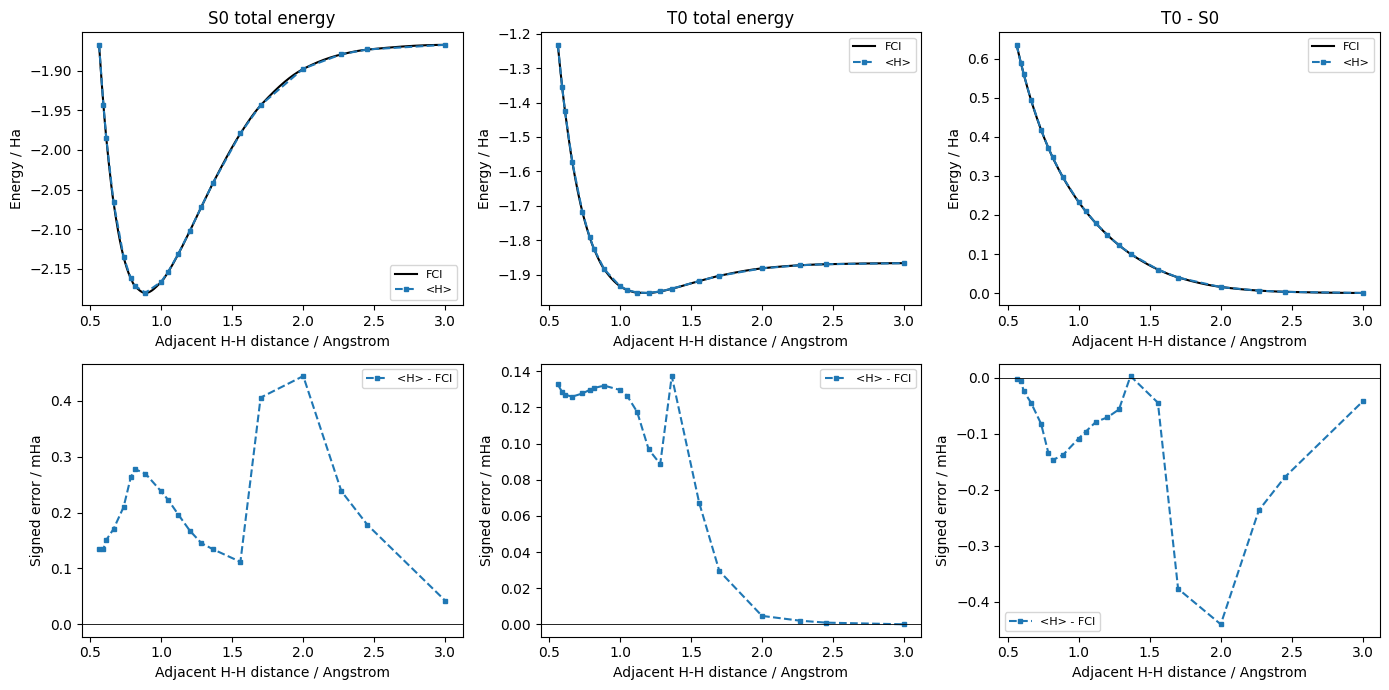

| R / Å | S₀ / Ha | T₀ / Ha | T₀−S₀ / Ha |
|---:|---:|---:|---:|
| 0.56164086 | -1.8671568567 | -1.2318342367 | 0.6353226200 |
| 0.59212035 | -1.9430207542 | -1.3546429183 | 0.5883778359 |
| 0.61244001 | -1.9850120354 | -1.4256759171 | 0.5593361183 |
| 0.66323916 | -2.0657489716 | -1.5717699210 | 0.4939790505 |
| 0.73435797 | -2.1348815330 | -1.7173747060 | 0.4175068270 |
| 0.78515711 | -2.1620097997 | -1.7903025971 | 0.3717072026 |
| 0.81563660 | -2.1717468460 | -1.8245730562 | 0.3471737897 |
| 0.88821403 | -2.1802357358 | -1.8841903738 | 0.2960453620 |
| 0.99851354 | -2.1664854388 | -1.9332144993 | 0.2332709394 |
| 1.04931269 | -2.1534156978 | -1.9445166743 | 0.2088990235 |
| 1.12043150 | -2.1309228008 | -1.9523729960 | 0.1785498047 |
| 1.20171013 | -2.1018074959 | -1.9533744580 | 0.1484330379 |
| 1.28298877 | -2.0714280890 | -1.9488906143 | 0.1225374747 |
| 1.36426741 | -2.0415671483 | -1.9411588912 | 0.1004082572 |
| 1.55730418 | -1.9790866977 | -1.9187323279 | 0.0603543698 |
| 1.69954179 | -1.9433846282 | -1.9034792995 | 0.0399053288 |
| 2.00000000 | -1.8973360679 | -1.8818709945 | 0.0154650733 |
| 2.26849226 | -1.8791138984 | -1.8728382200 | 0.0062756784 |
| 2.45136919 | -1.8731214602 | -1.8698420910 | 0.0032793692 |
| 3.00000000 | -1.8672490105 | -1.8668330990 | 0.0004159116 |

In [3]:
EXPECT_PREP_M = 8  # 4, 6, 8, 'exact'
EXPECT_RESULTS = expectation_pec(EXPECT_PREP_M)
plot_pec(EXPECT_RESULTS)
print_pec(EXPECT_RESULTS)
save_rows(EXPECT_RESULTS, 'outputs/04_expectation_pec.json')


## 2．Lを1ずつ増やして、BPE・BPDEからPECを描く

準備を `PHASE_PREP_M = 4, 6, 8, 'exact'`、時間発展を `PHASE_EVOLUTION_M = 8, 16, 32, 'exact'` から選びます。
第1節の設定とは独立です。全20構造で、$L=1,2,3,\ldots,\texttt{L\_MAX}$、$t=L\Delta t$、$\Delta t=0.1$ を計算します。
`L_SHOW` は図に重ねるLだけを選ぶ設定で、計算するLを間引くものではありません。

保存準備状態を $|\widetilde\psi_0\rangle,|\widetilde\psi_T\rangle$ として
$$a_k(L)=\langle\widetilde\psi_k|U^L|\widetilde\psi_k\rangle$$
を求め、補助位相βを1周期9点で走査します。
$$P_{\mathrm{BPE}}(\beta)=\frac{1+\mathrm{Re}(e^{i\beta}a_0)}{2},\qquad
P_{\mathrm{BPDE,C}}(\beta)=\frac{|a_0+e^{i\beta}a_T|^2}{4}.$$
定数＋cosβ＋sinβでフィットし、ピークの位相からS₀の電子エネルギーとT₀−S₀の差を読み取ります。
T₀のPECは、S₀の電子エネルギー＋差＋核反発で再構成します。

### 位相の2πの不定性

ピークの主値だけでは、エネルギーは $2\pi/t$ 周期でしか決まりません。
以前の実験と同様に、$t=0$から生存振幅の連続位相を確認して枝を選びます。整数Lの間を細分化する必要があれば自動的に確認します。
近似発展の補助時刻は保存ユニタリの主値logによる補間で、実回路を分数回実行する操作ではありません。
**これはシミュレーション上の追加情報であり、各Lでの9点測定だけから絶対エネルギーが決まったわけではありません。**
FCI値や〈H〉を正解の枝の選択には使いません。位相を確認できない場合や信号が平坦な場合は停止します。

上段に代表的なLのPEC、下段にFCIとの差を重ねます。次の図は全Lでの20点RMSEです。
Lを増やせば必ず誤差が減るわけではなく、近似発展の偏りや準備状態の混入成分が残り得ます。


In [4]:
PHASE_PREP_M = 8        # 4, 6, 8, 'exact'
PHASE_EVOLUTION_M = 32 # 8, 16, 32, 'exact'
L_MAX = 64             # 1〜1024。L=1,2,3,...,L_MAXをすべて計算
L_SHOW = [1, 2, 4, 8, 16, 32, 64]  # 図に重ねるL
L_SHOW = sorted({L for L in L_SHOW if 1 <= L <= L_MAX} | {L_MAX})
PHASE_RESULTS = phase_pec_scan(PHASE_PREP_M, PHASE_EVOLUTION_M, L_MAX)
save_rows(PHASE_RESULTS, 'outputs/04_phase_pec.json')


完了 R_0p56164086: R=0.56164 Å, L=1..64
完了 R_0p59212035: R=0.59212 Å, L=1..64
完了 R_0p61244001: R=0.61244 Å, L=1..64
完了 R_0p66323916: R=0.66324 Å, L=1..64
完了 R_0p73435797: R=0.73436 Å, L=1..64
完了 R_0p78515711: R=0.78516 Å, L=1..64
完了 R_0p81563660: R=0.81564 Å, L=1..64
完了 R_0p88821403: R=0.88821 Å, L=1..64
完了 R_0p99851354: R=0.99851 Å, L=1..64
完了 R_1p04931269: R=1.04931 Å, L=1..64
完了 R_1p12043150: R=1.12043 Å, L=1..64
完了 R_1p20171013: R=1.20171 Å, L=1..64
完了 R_1p28298877: R=1.28299 Å, L=1..64
完了 R_1p36426741: R=1.36427 Å, L=1..64
完了 R_1p55730418: R=1.55730 Å, L=1..64
完了 R_1p69954179: R=1.69954 Å, L=1..64
完了 R_2p00000000: R=2.00000 Å, L=1..64
完了 R_2p26849226: R=2.26849 Å, L=1..64
完了 R_2p45136919: R=2.45137 Å, L=1..64
完了 R_3p00000000: R=3.00000 Å, L=1..64


Quantity   <H> RMSE / mHa   final-L RMSE / mHa
S0             0.226839282            1.30690179
T              0.105363974           0.704937888
gap            0.162730512           0.763038069
準備=8, 発展=32, 最終L=64, R=20点
補助時間の最大分割数: 4
余弦フィットの最大残差: 7.771561172376096e-16


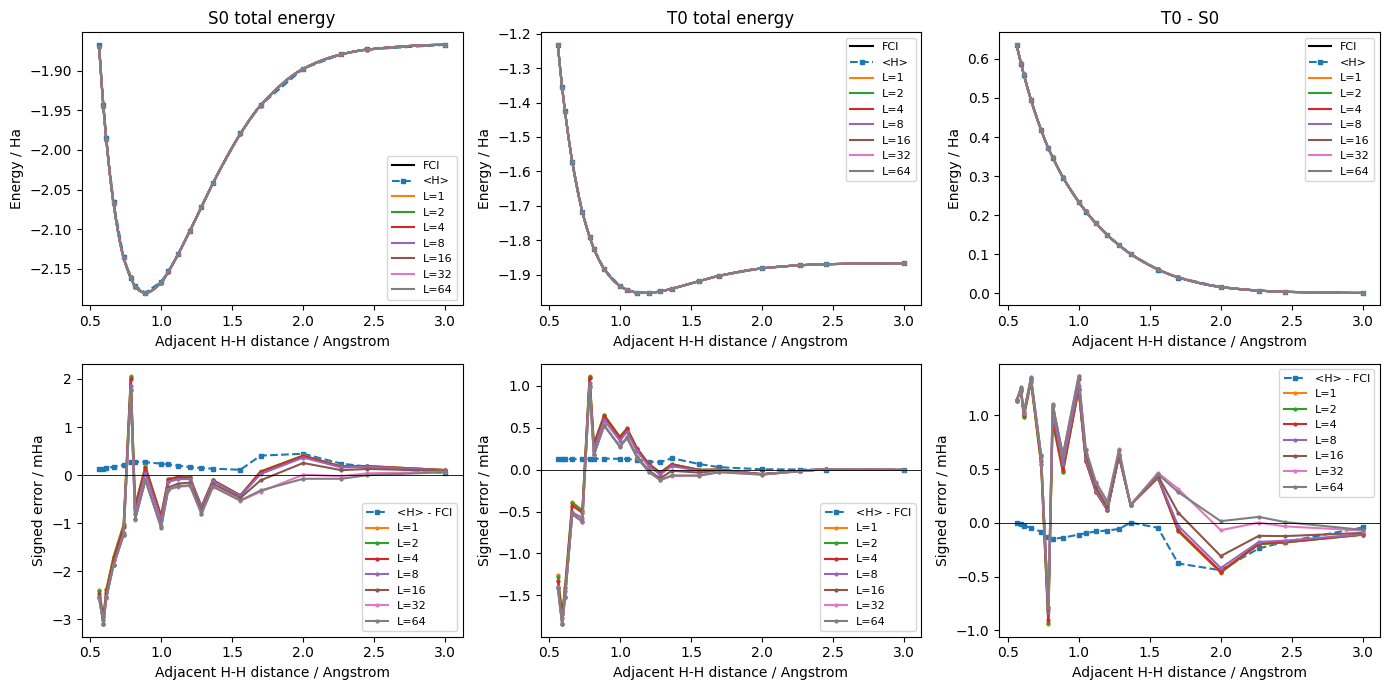

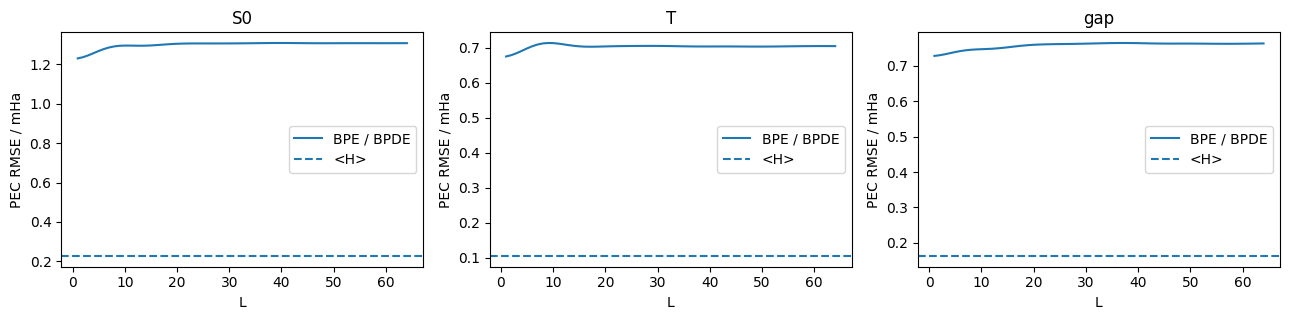

| R / Å | S₀ / Ha | T₀ / Ha | T₀−S₀ / Ha |
|---:|---:|---:|---:|
| 0.56164086 | -1.8698327703 | -1.2333756477 | 0.6364571227 |
| 0.59212035 | -1.9462584594 | -1.3566142086 | 0.5896442509 |
| 0.61244001 | -1.9877171004 | -1.4273288163 | 0.5603882840 |
| 0.66323916 | -2.0677973533 | -1.5724258953 | 0.4953714581 |
| 0.73435797 | -2.1363405141 | -1.7181182681 | 0.4182222460 |
| 0.78515711 | -2.1604999736 | -1.7894389156 | 0.3710610580 |
| 0.81563660 | -2.1729416511 | -1.8245191978 | 0.3484224533 |
| 0.88821403 | -2.1806091783 | -1.8837923279 | 0.2968168503 |
| 0.99851354 | -2.1678168554 | -1.9330719173 | 0.2347449381 |
| 1.04931269 | -2.1539376387 | -1.9442651170 | 0.2096725217 |
| 1.12043150 | -2.1313479013 | -1.9523480076 | 0.1789998937 |
| 1.20171013 | -2.1021854540 | -1.9534933350 | 0.1486921190 |
| 1.28298877 | -2.0723720847 | -1.9491039046 | 0.1232681801 |
| 1.36426741 | -2.0419356029 | -1.9413638847 | 0.1005717182 |
| 1.55730418 | -1.9797250528 | -1.9188724501 | 0.0608526027 |
| 1.69954179 | -1.9441086677 | -1.9035397154 | 0.0405689523 |
| 2.00000000 | -1.8978565564 | -1.8819351633 | 0.0159213931 |
| 2.26849226 | -1.8794273343 | -1.8728587583 | 0.0065685760 |
| 2.45136919 | -1.8733022049 | -1.8698373308 | 0.0034648740 |
| 3.00000000 | -1.8672298096 | -1.8668364330 | 0.0003933766 |

In [5]:
plot_pec(PHASE_RESULTS, phase=True, show_l=L_SHOW)
plot_l_errors(PHASE_RESULTS)
FINAL_PEC = [r for r in PHASE_RESULTS if r['L'] == L_MAX]
print(f'準備={PHASE_PREP_M}, 発展={PHASE_EVOLUTION_M}, 最終L={L_MAX}, R={len(FINAL_PEC)}点')
print_pec(FINAL_PEC, kind='phase')
print('補助時間の最大分割数:', max(r['phase_certificate']['subdivisions'] for r in FINAL_PEC))
print('余弦フィットの最大残差:', max(r['max_fit_residual'] for r in PHASE_RESULTS))


## 時間を延ばすとき（$L$を大きくするとき）の振る舞い

まず**厳密な時間発展**を考え、Rを固定して電子Hamiltonianの固有状態で準備状態を展開します。
$$H|E_n\rangle=E_n|E_n\rangle,\qquad
|\widetilde\psi\rangle=\sum_n c_n|E_n\rangle,\qquad p_n=|c_n|^2,\quad\sum_n p_n=1.$$
期待値は、混入した固有状態も含むエネルギーの重み付き平均です。
$$\overline E=\langle H\rangle=\sum_n p_nE_n.$$
ユニタリな時間発展で重み$p_n$は変わりません。一方、位相実験では生存振幅
$$a(t)=\langle\widetilde\psi|e^{-iHt}|\widetilde\psi\rangle
=\sum_n p_ne^{-iE_nt}$$
の位相を読み、$t=0$から連続につないだ位相$\Phi(t)$から
$$E_{\mathrm{phase}}(t)=-\frac{\Phi(t)}{t}$$
を求めています。期待値と位相は、同じ準備状態から異なる情報を取り出しています。

### 短時間：位相の傾きは期待値

$t=0$付近で生存振幅の対数を展開すると、
$$\log a(t)=-i\overline E\,t-\frac{\sigma_E^2t^2}{2}
+\frac{i\kappa_3t^3}{6}+O(t^4),$$
$$\sigma_E^2=\sum_n p_n(E_n-\overline E)^2,\qquad
\kappa_3=\sum_n p_n(E_n-\overline E)^3.$$
したがって、位相から得るエネルギーは
$$\boxed{E_{\mathrm{phase}}(t)=\overline E-\frac{\kappa_3}{6}t^2+O(t^4)}.$$
**短時間では、位相から読んでもほぼ期待値になります。**
本演習の$L=1$は$t=\Delta t=0.1$です。厳密発展で高次の項が小さければ期待値とほぼ重なりますが、有限時間での完全一致を意味しません。

### 長時間：目的の固有状態が優勢なら、誤差を時間で割れる

目的の固有状態$|E_*\rangle$の重みが$p_*>1/2$であるとします。
$$a(t)=e^{-iE_*t}\left[p_*+\sum_{n\ne *}p_ne^{-i(E_n-E_*)t}\right]
=e^{-iE_*t}p_*[1+z(t)],$$
$$|z(t)|\le\rho\equiv\frac{1-p_*}{p_*}<1.$$
$1+z(t)$は原点を囲まないため、その位相$\delta(t)=\arg[1+z(t)]$は一定範囲に収まります。
$$|\delta(t)|\le\arcsin\rho,\qquad
\Phi(t)=-E_*t+\delta(t).$$
よって、連続位相から求めたエネルギーの誤差には
$$\boxed{|E_{\mathrm{phase}}(t)-E_*|
\le\frac{\arcsin[(1-p_*)/p_*]}{t}
=\frac{\arcsin[(1-p_*)/p_*]}{L\Delta t}}$$
という上限があります。

期待値の誤差$\overline E-E_*=\sum_{n\ne *}p_n(E_n-E_*)$は、同じ準備状態なら一定です。
一方、位相の混入によるずれ$\delta(t)$は有界なので、**十分長い時間では、それを$t$で割る位相推定が期待値より正しい固有エネルギーに近づけます。**
改善するのはエネルギーの推定値です。準備状態のfidelityが時間発展だけで上がるわけではありません。

S₀とT₀の両方で上の条件が成り立てば、BPDEの差についても
$$\Delta E_{\mathrm{phase}}(t)=\frac{\Phi_0(t)-\Phi_T(t)}{t},\qquad
|\Delta E_{\mathrm{phase}}-\Delta E|
\le\frac{\arcsin\rho_0+\arcsin\rho_T}{t}$$
と評価できます。PECには核反発$E_{\mathrm{nuc}}(R)$を足します。差では相殺されます。

### この改善が成り立つ条件

- $p_*>1/2$は十分条件です。これを満たさない準備状態には、上の収束の保証はありません。
- 位相の枝を正しく追跡する必要があります。主値の位相だけを$t$で割ると、$2\pi/t$の取り違えが起こります。
- 上限が$1/t$で減っても、個々のLの誤差は振動し得ます。Lを1増やすたびに単調に良くなる、という主張ではありません。
- 近似発展$U_{\mathrm{app}}=e^{-iH_{\mathrm{eff}}\Delta t}$を使うと、長時間で読まれるのは$H_{\mathrm{eff}}$の固有エネルギーです。対応する固有成分が優勢でも、$E_{\mathrm{phase}}-E_*=(\widetilde E_*-E_*)+O(1/t)$となり、発展近似の偏りは残り得ます。

**この効果を切り分けるには、まず `PHASE_EVOLUTION_M = 'exact'` とし、準備Mだけを変えてL依存性を比較してください。**
次に発展をM=8・16・32へ変えれば、長時間化の効果と発展回路の近似誤差を比較できます。
本演習はshot noiseなしのシミュレーションであり、上の説明には有限shotsや実機ノイズの誤差を含めていません。